In [1]:
"""
NEW FLUID MODEL: KEROSENE + GOX + GN2 + LOX

METS Feed System — FullFlow model v2
====================================
GOX / kerosene feed lines from regulators to the Hopper torch chamber, and
LOX / kerosene feed lines from the tanks to the Elytra torch igniter chamber, and
LOX / kerosene feed lines from the tanks to the Elytra gas generator injector inlet.
Each Elytra torch and Elytra GG function sits right after its Hopper twin and follows the same steps.
GN2 is not modeled as its own leg yet: PR-REG (PR-REG-1) simply sets the fuel tank
pressure and PR-REG-2 the LOX tank pressure (no GN2 flow losses in steady state).

GOX topology (backbone):
  O-REG outlet → O-TUBE-1 → OMV → O-TUBE-2 → O-INJ (choked) → Chamber

LOX topology (backbone, Elytra torch; O-PV and the venturi are for the gas generator only):
  Tank (= PR-REG-2 setpoint) → C-TUBE-1 → C-TUBE-2 → T-OV → C-TUBE-3 → O-INJ (liquid) → Chamber

LOX topology (Elytra GG; venturi added later). The model ends at the GG injector inlet:
  Tank (= PR-REG-2 setpoint) → C-TUBE-1 → O-PV → C-TUBE-2 → C-TUBE-3 → GG injector inlet (fixed)

Kerosene topology (backbone):
  Tank (= PR-REG setpoint) → F-TUBE-1 → FMV → F-TUBE-2 → F-INJ → Chamber
  (Elytra GG: ends at the GG injector inlet, no F-INJ / chamber)

Each TUBE = straight-tube friction (DarcyWeisbach + Churchill) with its
fittings (bends, tees, unions) folded in as an equivalent length.

Chamber:
  Pc = (mdot_ox + mdot_fuel) * c* / A_throat   ← couples the two legs

Hopper targets (PDR / HopperTorchSizing Excel):
  mdot_ox = 19.29 g/s, mdot_fuel = 10.71 g/s, MR = 1.8, Pc = 200 psia
Elytra targets (Elytra Torch Igniter PDR, updated):
  mdot_ox = 9.4 g/s LOX, mdot_fuel = 5.2 g/s, MR = 1.81, Pc = 265 psia
Elytra GG targets (Elytra team):
  mdot_ox = 37.5 g/s LOX, mdot_fuel = 62.5 g/s, MR = 0.6, injector inlet = 100 psia
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from fullflow import (
    Network, State, Balance,
    SteadyState,
    DischargeCoefficient, CompressibleOrifice,
    DarcyWeisbach, Churchill,
)  # pip install fullflow thermoprop
import thermoprop as tp

script_dir = Path.cwd()
PSI_TO_PA = 6894.76
G_TO_KG = 1e-3

In [2]:
# ─────────────────────────────────────────────────────────────────────
# CUSTOM COMPONENTS / CONVERSIONS
# ─────────────────────────────────────────────────────────────────────
# Converting Cv and K into an effective CdA, so every
# restriction uses FullFlow's built-in DischargeCoefficient (liquid) or
# CompressibleOrifice (gas).

def cv_to_cda(Cv: float) -> float:
    """
    Convert a valve flow coefficient Cv (US, gpm / sqrt(psi)) to an
    equivalent effective area CdA [m^2].

    From Q[gpm] = Cv * sqrt(dP[psi] / SG) and mdot = CdA * sqrt(2 * rho * dP):
        CdA = Cv * 6.309e-5 * sqrt(999 / 6894.76) / sqrt(2) ≈ Cv * 1.70e-5 m^2
    """
    return Cv * 6.309e-5 * np.sqrt(999.0 / PSI_TO_PA) / np.sqrt(2.0)


def k_to_cda(K: float, area: float) -> float:
    """Minor-loss coefficient K (dP = K * rho * v^2 / 2) → effective CdA [m^2]."""
    return area / np.sqrt(K)

In [3]:
# ─────────────────────────────────────────────────────────────────────
# TEST ARTICLE
# ─────────────────────────────────────────────────────────────────────

def make_hopper_torch() -> dict:
    Pc_pa      = 200.0 * PSI_TO_PA    # Hopper PDR
    D_throat_m = 0.1952 * 0.0254      # Hopper PDR
    A_throat   = np.pi * D_throat_m**2 / 4
    mdot_ox    = 19.29 * G_TO_KG      # Hopper PDR
    mdot_fuel  = 10.71 * G_TO_KG      # Hopper PDR
    c_star     = Pc_pa * A_throat / (mdot_ox + mdot_fuel)   # = 887 m/s

    return {
        'name':           'Hopper Torch',
        'target_mdot_ox': mdot_ox,       # [kg/s]
        'target_mdot_fu': mdot_fuel,     # [kg/s]
        'target_MR':      mdot_ox / mdot_fuel,
        'target_Pc':      Pc_pa,         # [Pa]
        'A_throat':       A_throat,      # [m^2]
        'c_star':         c_star,        # [m/s]  
        'CdA_ox_inj':     2.46e-6,       # [m^2]  HopperTorchSizing Testing Pressure Ladder sheet, "OX Injector - O-INJ" CdA (choked)
        'CdA_fu_inj':     3.33e-7,       # [m^2]  # PLACEHOLDER: back-calculated for ~100 psid at 10.71 g/s from Hopper Torch PDR
                                         #        "Injector Parameters" slide (FU orifices ~100 psid). The Testing Pressure Ladder's
                                         #        F-INJ cell (4.79e-7) gives only ~48 psid. Replace with as-built CdA / cold-flow data.
    }


def print_hopper_torch_test_article(ta: dict):
    print()
    print("=" * 55)
    print(f"  TEST ARTICLE: {ta['name']}")
    print("=" * 55)
    print(f"  Target mdot ox   = {ta['target_mdot_ox']*1000:.2f} g/s")
    print(f"  Target mdot fuel = {ta['target_mdot_fu']*1000:.2f} g/s")
    print(f"  Target MR        = {ta['target_MR']:.2f}")
    print(f"  Target Pc        = {ta['target_Pc']/PSI_TO_PA:.1f} psia")
    print(f"  Throat D         = {np.sqrt(4*ta['A_throat']/np.pi)/0.0254:.4f} in")
    print(f"  c* (actual)      = {ta['c_star']:.1f} m/s")
    print("=" * 55)


# LOX / kerosene, single O-F-O triplet element: 2 LOX orifices + 1 fuel orifice.
# Fuel goes through the stand's FMV, which is also the torch's fuel solenoid (one valve, not two).

def make_elytra_torch() -> dict:
    Pc_pa      = 265.0 * PSI_TO_PA    # [Pa] updated Elytra Torch spec (PDR v1 slide said 235 psia; raised to 265 psia per Elytra team)
    mdot_ox    = 9.4  * G_TO_KG       # [kg/s] Elytra Torch PDR (updated) Specifications 1.2 "LOX M-dot 9.4 g/s"
    mdot_fuel  = 5.2  * G_TO_KG       # [kg/s] Elytra Torch PDR (updated) Specifications 1.3 "Fuel M-dot 5.2 g/s"

    d_ox_hole  = 0.521e-3             # [m] Elytra Torch PDR Injector Design "LOX Hole Diameter 0.521 mm"
    n_ox_holes = 2                    # [-] single O-F-O triplet element → 2 LOX orifices (confirmed by Elytra team)
    Cd_ox      = 0.803                # [-] Elytra Torch PDR Analysis: CFD "LOX orifices had a Cd of about 0.803" (sizer used 0.81)
    d_fu_hole  = 0.599e-3             # [m] Elytra Torch PDR Injector Design "Fuel Hole Diameter 0.599 mm"
    n_fu_holes = 1                    # [-] single triplet element → 1 fuel orifice (confirmed by Elytra team)
    Cd_fu      = 0.67                 # [-] Elytra Torch PDR Analysis: CFD "Fuel orifice had a lower Cd of 0.67 instead of 0.81"
                                      #     # PLACEHOLDER until water / cold-flow CdA characterization (PDR waterflow con-ops)

    # Chamber closure Pc = mdot_total * c* / A_t only needs the ratio c*/A_t, anchored here at the
    # design point (Pc 265 psia at 14.6 g/s). The PDR's 65% c* efficiency is therefore built in, and
    # no throat diameter is needed. Predictions away from the design point assume c* stays constant.
    c_star_over_At = Pc_pa / (mdot_ox + mdot_fuel)       # [1/(m s)] = c*/A_t

    return {
        'name':           'Elytra Torch',
        'target_mdot_ox': mdot_ox,
        'target_mdot_fu': mdot_fuel,
        'target_MR':      mdot_ox / mdot_fuel,     # 1.81 (PDR Specifications 1.5 "MR 1.8")
        'target_Pc':      Pc_pa,
        'c_star_over_At': c_star_over_At,
        'CdA_ox_inj':     Cd_ox * n_ox_holes * np.pi * d_ox_hole**2 / 4,   # [m^2] 3.42e-7
        'CdA_fu_inj':     Cd_fu * n_fu_holes * np.pi * d_fu_hole**2 / 4,   # [m^2] 1.89e-7
        'tov_Cv':         0.040,                   # T-OV = torch oxygen valve: Gems DN2001-05LV-R-G6-204, 0.040" orifice.
                                                   # Elytra Torch PDR (updated) "GEMS D-Series ... CV of 0.04"; LOX Pressure Ladder CSV "Actual Cv"
        'uses_tov':       True,                    # T-OV is in the torch LOX line
        'uses_opv':       False,                   # O-PV is not in the torch LOX line: it is used for the gas generator only
                                                   # (Elytra team, Nov 13). T-OV is the only LOX valve for the torch.
        'P_inj_in_target_psia': 312.0,             # LOX Pressure Ladder CSV: end of the LOX feed system (injector inlet)
        'holes': {'ox': (n_ox_holes, d_ox_hole, Cd_ox), 'fu': (n_fu_holes, d_fu_hole, Cd_fu)},
    }


def print_elytra_torch_test_article(ta: dict):
    print()
    print("=" * 62)
    print(f"  TEST ARTICLE: {ta['name']}")
    print("=" * 62)
    print(f"  Target mdot LOX / fuel = {ta['target_mdot_ox']*1000:.2f} / {ta['target_mdot_fu']*1000:.2f} g/s")
    print(f"  Target MR              = {ta['target_MR']:.2f}")
    print(f"  Target Pc              = {ta['target_Pc']/PSI_TO_PA:.1f} psia")
    for leg, rho, mdot, label in (('ox', RHO_LOX, ta['target_mdot_ox'], 'LOX '),
                                  ('fu', RHO_KERO, ta['target_mdot_fu'], 'Fuel')):
        n, d, Cd = ta['holes'][leg]
        CdA = ta['CdA_ox_inj'] if leg == 'ox' else ta['CdA_fu_inj']
        dP = (mdot / CdA)**2 / (2 * rho) / PSI_TO_PA
        print(f"  {label} injector: {n} x {d*1e3:.3f} mm, Cd {Cd:.3f} → CdA {CdA:.3e} m^2,"
              f" dP {dP:5.1f} psi ({100*dP/(ta['target_Pc']/PSI_TO_PA):.0f}% of Pc)"
              f" → inlet {ta['target_Pc']/PSI_TO_PA + dP:.1f} psia")
    print("=" * 62)


def make_elytra_gg() -> dict:
    """
    Elytra gas generator (turbopump), LOX / kerosene, very fuel rich.
    The METS model ends at the GG injector inlet: both legs are held at the target inlet pressure
    and the GG hardware (injector, chamber, turbine) is outside the model. So there is no injector
    CdA and no chamber closure, and the two legs are not coupled to each other.
    """
    mdot_ox   = 37.5 * G_TO_KG       # [kg/s] Elytra GG LOX mdot (Elytra team, Nov 13)
    mdot_fuel = 62.5 * G_TO_KG       # [kg/s] Elytra GG fuel mdot (Elytra team, Nov 13) → MR 0.6
    P_inj_in  = 100.0 * PSI_TO_PA    # [Pa] target GG injector inlet pressure, both legs (Elytra team). Taken as psia
                                     #      # PLACEHOLDER: confirm psia vs psig (psig = 114.7 psia)
    return {
        'name':             'Elytra GG',
        'target_mdot_ox':   mdot_ox,
        'target_mdot_fu':   mdot_fuel,
        'target_MR':        mdot_ox / mdot_fuel,     # 0.60
        'target_P_inj_in':  P_inj_in,                # end of the model (fixed boundary on both legs)
        'CdA_ox_inj':       None,                    # GG injector not modeled: LOX leg ends at the injector inlet
        'CdA_fu_inj':       None,                    # GG injector not modeled: fuel leg ends at the injector inlet
        'uses_opv':         True,                    # O-PV is the GG LOX valve: same Gems D-series cryo solenoid as T-OV,
                                                     # Cv 0.04 (Elytra Torch PDR) → STAND['opv_Cv']
        'uses_tov':         False,                   # T-OV is the torch's own valve; not in the GG line
    }


def print_elytra_gg_test_article(ta: dict):
    print()
    print("=" * 62)
    print(f"  TEST ARTICLE: {ta['name']}")
    print("=" * 62)
    print(f"  Target mdot LOX / fuel = {ta['target_mdot_ox']*1000:.2f} / {ta['target_mdot_fu']*1000:.2f} g/s")
    print(f"  Target MR              = {ta['target_MR']:.2f}")
    print(f"  Injector inlet (both)  = {ta['target_P_inj_in']/PSI_TO_PA:.1f} psia  (end of the model)")
    for label, mdot, rho in (('LOX ', ta['target_mdot_ox'], RHO_LOX), ('Fuel', ta['target_mdot_fu'], RHO_KERO)):
        print(f"  {label} line velocity     = {mdot/(rho*TUBE_AREA):.2f} m/s in 1/4\" x 0.035\" tube")
    print("=" * 62)

In [4]:
# ─────────────────────────────────────────────────────────────────────
# FLUID PROPERTY HELPERS
# ─────────────────────────────────────────────────────────────────────
GOX_GAMMA = 1.40      # ideal diatomic gas value
GOX_R     = 259.8     # [J/kg-K] 8314 / 32.00 (O2 molar mass, CoolProp);
RHO_KERO  = 800.0     # [kg/m^3] # PLACEHOLDER: typical RP-1 / Jet-A at ~20 C (~800-820). 
T_AMB     = 293.0     # [K] HopperTorchSizing Testing Pressure Ladder sheet (OX / FU temperature = 293 K)
MU_GOX    = 2.1e-5    # [Pa-s] CoolProp O2 at 293 K, 1-4.5 MPa (2.05-2.13e-5)
MU_KERO   = 1.6e-3    # [Pa-s] # PLACEHOLDER: typical kerosene at 20 C (~2 cSt); CoolProp n-dodecane gives 1.53e-3

# LOX (Elytra). Source: "METS LOX Feed System Design — LOX Pressure Ladder 1" sheet (CSV export).
RHO_LOX   = 1141.0    # [kg/m^3] LOX Pressure Ladder CSV "LOX Density" (literature, 90 K). Constant: LOX treated as incompressible
MU_LOX    = 1.9e-4    # [Pa-s] LOX Pressure Ladder CSV "LOX Dynamic Viscosity"
T_LOX     = 90.0      # [K] LOX Pressure Ladder CSV "Fluid Temperature" (LOX sat temp). Documentation only: rho and mu are fixed

# GOX is treated as an ideal gas everywhere (rho = P / R T). At ~650 psia
# real O2 is ~3% denser (Z ≈ 0.97); good enough for a first model.

def gox_density(P: State, T: float = T_AMB) -> State:
    """Live ideal-gas density State: recomputed whenever P changes."""
    return P / (GOX_R * T)


def real_gox_density(pressure_pa: float, temperature: float = T_AMB) -> float:
    """Real-gas check value via ThermoProp/CoolProp (not used in the solve)."""
    return tp.Fluid('oxygen', pressure=pressure_pa, temperature=temperature).density

In [5]:
# ─────────────────────────────────────────────────────────────────────
# STAND HARDWARE (shared by every test article)
# ─────────────────────────────────────────────────────────────────────
TUBE_ID = (0.25 - 2 * 0.035) * 0.0254     # METS BOM: 1/4" OD x 0.035" WT SS304 seamless tube → ID 4.57 mm
TUBE_AREA      = np.pi * TUBE_ID**2 / 4
TUBE_ROUGHNESS = 1.5e-6   # [m] standard handbook value for drawn stainless tubing (Moody chart tables)

# Loss coefficient per fitting   # PLACEHOLDER: handbook-typical values (Crane TP-410 order of
# magnitude). Replace with fitting-vendor data or cold-flow-measured line dP.
K_FITTING = {
    'bend':       0.25,   # tube bent 90 deg, bend radius ~3 D
    'elbow':      0.75,   # 90 deg AN/JIC elbow fitting
    'tee_run':    0.40,   # flow passing straight through a tee
    'tee_branch': 1.00,   # flow turning through a tee
    'union':      0.08,   # straight union / adapter
}

STAND = {
    # GOX leg
    'P_gox_bottle_psia': 2000.0,
    # Tube runs   # PLACEHOLDER: Measure once METS is built.
    # L = straight length [m], dz = height gain [m], fittings = counts
    'o_segments': [
        {'name': 'O-TUBE-1', 'L': 0.55, 'dz': 0.0,     # O-REG → vent tee → OMV
         'fittings': {'tee_run': 1, 'union': 2}},
        {'name': 'O-TUBE-2', 'L': 0.60, 'dz': 0.0,     # OMV → torch (+~1 ft to torch)
         'fittings': {'bend': 2, 'union': 2}},
    ],
    'omv_Cv':            0.12,    # AliExpress 1 ksi solenoid datasheet (METS BOM)
    # Fuel leg
    'P_gn2_bottle_psia': 2000.0,
    'f_segments': [               # PLACEHOLDER: same source as o_segments (wall drawing + hand P&ID)
        {'name': 'F-TUBE-1', 'L': 0.95, 'dz': 0.30,    # tank → drain tee → FMV (rises ~1 ft)
         'fittings': {'tee_run': 1, 'bend': 4, 'union': 2}},
        {'name': 'F-TUBE-2', 'L': 0.60, 'dz': 0.0,     # FMV → FPT / purge tee → F-INJ
         'fittings': {'tee_run': 1, 'bend': 1, 'union': 2}},
    ],
    'fmv_Cv':            0.12,    # AliExpress 1 ksi solenoid datasheet (METS BOM), same valve as OMV
    # LOX leg (Elytra). Source: "METS LOX Feed System Design — LOX Pressure Ladder 1" sheet (CSV export).
    # PR-REG-2 is fed from the same GN2 bottle as PR-REG (P_gn2_bottle_psia).
    # Tube runs: lengths and K from the CSV rows, grouped into three runs between the valves. The CSV flags
    # every length / fitting "unknown" → # PLACEHOLDER until the LOX leg CAD exists. The K values are the
    # CSV's own (tee 0.9, elbow 1.5), so they are given as 'K' instead of K_FITTING counts.
    # Differences from the CSV: real 0.18" tube ID (CSV used ID = OD = 0.25"); tank head ADDS pressure at
    # the bottom outlet (the CSV subtracted it); the CSV's 0.3 m "Elevation Change" (listed under the
    # Venturi, never applied) is applied as a 0.3 m drop from O-PV down to the torch (P&ID v1.3 draws the
    # UUT below O-PV) # PLACEHOLDER: direction/height from CAD.
    'lox_tank_liquid_height': 0.125476,   # [m] CSV "Tank Height" (1.161 L tank, from part list). Full tank assumed
    'c_segments': [
        {'name': 'C-TUBE-1', 'L': 0.127 + 0.1524, 'dz': -0.125476,   # tank → tee (O-FILL branch) → O-PV; dz = -tank height (head)
         'K': 0.9},                                                # CSV rows Tank→bend, bend (tee), bend→O-PV
        {'name': 'C-TUBE-2', 'L': 0.2 + 0.2 + 0.127, 'dz': -0.3,     # O-PV position → elbow 1 → elbow 2 → T-OV
         'K': 3 * 1.5 + K_FITTING['tee_run']},                      # CSV rows O-PV→elbow 1 ... elbow 2→T-OV (3 elbows)
                                                                   # + relief-valve tee after O-PV (P&ID v1.3), run through
                                                                   #   # PLACEHOLDER K
        {'name': 'C-TUBE-3', 'L': 0.127, 'dz': 0.0,                  # T-OV → torch LOX inlet. CSV row T-OV→injector
         'K': 0.0},
    ],
    'opv_Cv':            0.040,   # Gas generator only (not in the Elytra torch line: ta['uses_opv']). Gems DN2001-05LV-R-G6-204, 0.040" orifice. LOX Pressure Ladder CSV "Actual Cv";
                                  # Elytra Torch PDR (updated) "CV of 0.04"; LOX Candidates BOM: 2 owned (O-PV and T-OV)
    'lox_valve_meop_psia':   1000.0,   # Elytra Torch PDR (updated): GEMS D-series max operating pressure 1000 psi
    'lox_protected_leg_psia': 336.7,   # Press Relief Design CSV: "P2 = 336.7 psi, protected leg" (PR-REG-2 outlet design point)
    # Ratings
    'component_rating_psia': 1000.0,   # METS BOM: 1 ksi solenoids, PTs, ball valves (PDR lists solenoid MEOP 1160 psia)
}

In [6]:
# ─────────────────────────────────────────────────────────────────────
# FEED SYSTEM BUILDER
# ─────────────────────────────────────────────────────────────────────

def add_tube_segment(net: Network, seg: dict, P_up: State, rho: State,
                     mu: float, mdot_guess: float):
    """
    NEW. One tube run = straight-tube friction + its fittings, as one pipe:
        P_up → [DarcyWeisbach, f from Churchill] → P_out
    Fittings are folded in as an equivalent length,
        L_eq = L + K_total * D / f    →    total loss = (f L/D + K_total) rho v^2 / 2
    so one smooth component carries both losses (no extra node).
    Returns the outlet pressure State and the pipe component.

    ADDED (LOX leg): a segment may give its total loss coefficient directly as seg['K']
    instead of 'fittings' counts.
    """
    name  = seg['name']
    P_out = State(P_up.value * 0.995, bounds=(1e4, None))
    mdot  = State(mdot_guess)        # pipe mass flow (solver unknown)
    f     = State(0.02)              # Darcy friction factor (Churchill output: continuous laminar → turbulent)

    Churchill(f"{name} friction", net,
        mass_flow=mdot, friction_factor=f, hydraulic_diameter=TUBE_ID,
        dynamic_viscosity=mu, cross_sectional_area=TUBE_AREA,
        roughness=TUBE_ROUGHNESS)

    if 'K' in seg:
        K_total = seg['K']
    else:
        K_total = sum(K_FITTING[kind] * n for kind, n in seg['fittings'].items())
    L_eq    = seg['L'] + K_total * TUBE_ID / f      # live: updates with f

    PIPE = DarcyWeisbach(name, net,
        mass_flow=mdot, upstream_pressure=P_up, downstream_pressure=P_out,
        length=L_eq, hydraulic_diameter=TUBE_ID, density=rho,
        cross_sectional_area=TUBE_AREA, friction_factor=f,
        height_change=seg['dz'])
    return P_out, PIPE


def build_gox_leg(net: Network, P_reg: State, P_cc: State, stand: dict, ta: dict):
    """GOX: O-REG outlet → O-TUBE-1 → OMV → O-TUBE-2 → O-INJ → chamber."""
    T_ox       = State(T_AMB)
    mdot_scale = 0.02
    seg1, seg2 = stand['o_segments']
    guess      = ta['target_mdot_ox']

    # O-TUBE-1: regulator → OMV inlet
    P_omv_in, PIPE1 = add_tube_segment(net, seg1, P_reg, gox_density(P_reg), MU_GOX, guess)
    P_omv_out = State(P_reg.value * 0.70, bounds=(1e4, None))

    OMV = CompressibleOrifice("OMV", net,
        upstream_total_pressure=P_omv_in, upstream_total_temperature=T_ox,
        downstream_pressure=P_omv_out,   discharge_coefficient=1.0,
        cross_sectional_area=cv_to_cda(stand['omv_Cv']),
        gas_constant=GOX_R,          specific_heat_ratio=GOX_GAMMA)

    # O-TUBE-2: OMV outlet → injector inlet
    P_inj_in, PIPE2 = add_tube_segment(net, seg2, P_omv_out, gox_density(P_omv_out), MU_GOX, guess)

    INJ = CompressibleOrifice("O-INJ", net,
        upstream_total_pressure=P_inj_in, upstream_total_temperature=T_ox,
        downstream_pressure=P_cc,    discharge_coefficient=1.0,
        cross_sectional_area=ta['CdA_ox_inj'],
        gas_constant=GOX_R,          specific_heat_ratio=GOX_GAMMA)

    # ── Node mass balances (continuity): mdot_in = mdot_out ──────────
    Balance("bal_o_omv_in",  net, variable=P_omv_in,
            function=(PIPE1.mass_flow - OMV.mass_flow) / mdot_scale)
    Balance("bal_o_omv_out", net, variable=P_omv_out,
            function=(OMV.mass_flow - PIPE2.mass_flow) / mdot_scale)
    Balance("bal_o_inj_in",  net, variable=P_inj_in,
            function=(PIPE2.mass_flow - INJ.mass_flow) / mdot_scale)

    nodes = {'O-REG outlet': P_reg, 'OMV in': P_omv_in,
             'OMV out': P_omv_out, 'Inj in': P_inj_in}
    branches = {'O-TUBE-1': PIPE1, 'OMV': OMV, 'O-TUBE-2': PIPE2, 'O-INJ': INJ}
    return INJ, nodes, branches


def build_fuel_leg(net: Network, P_tank: State, P_cc: State, stand: dict, ta: dict):
    """Kerosene: tank → F-TUBE-1 → FMV → F-TUBE-2 → F-INJ → chamber.
    If ta['CdA_fu_inj'] is None (Elytra GG) there is no injector: F-TUBE-2 ends at P_cc,
    which is then the fixed injector-inlet pressure, and the leg's mass flow is F-TUBE-2's."""
    rho        = State(RHO_KERO)
    mdot_scale = 0.01
    seg1, seg2 = stand['f_segments']
    guess      = ta['target_mdot_fu']

    def restriction(name, up, down, CdA):
        return DischargeCoefficient(name, net,
            upstream_pressure=up, downstream_pressure=down, density=rho,
            discharge_coefficient=1.0, cross_sectional_area=CdA)

    # F-TUBE-1: tank → FMV inlet
    P_fmv_in, PIPE1 = add_tube_segment(net, seg1, P_tank, rho, MU_KERO, guess)
    P_fmv_out = State(P_tank.value * 0.98, bounds=(1e4, None))
    FMV = restriction("FMV", P_fmv_in, P_fmv_out, cv_to_cda(stand['fmv_Cv']))

    # F-TUBE-2: FMV outlet → F-INJ inlet
    P_inj_in, PIPE2 = add_tube_segment(net, seg2, P_fmv_out, rho, MU_KERO, guess)

    Balance("bal_f_fmv_in",  net, variable=P_fmv_in,
            function=(PIPE1.mass_flow - FMV.mass_flow) / mdot_scale)
    Balance("bal_f_fmv_out", net, variable=P_fmv_out,
            function=(FMV.mass_flow - PIPE2.mass_flow) / mdot_scale)

    nodes = {'Tank (PR-REG)': P_tank, 'FMV in': P_fmv_in, 'FMV out': P_fmv_out}
    branches = {'F-TUBE-1': PIPE1, 'FMV': FMV, 'F-TUBE-2': PIPE2}
    if ta['CdA_fu_inj'] is None:          # Elytra GG: model ends at the injector inlet (fixed P_cc)
        Balance("bal_f_end", net, variable=P_inj_in, function=(P_inj_in - P_cc) / 1.0e5)
        return PIPE2, nodes, branches
    INJ = restriction("F-INJ", P_inj_in, P_cc, ta['CdA_fu_inj'])
    Balance("bal_f_inj_in",  net, variable=P_inj_in,
            function=(PIPE2.mass_flow - INJ.mass_flow) / mdot_scale)
    nodes['Inj in'] = P_inj_in
    branches['F-INJ'] = INJ
    return INJ, nodes, branches


def build_lox_leg(net: Network, P_tank: State, P_cc: State, stand: dict, ta: dict):
    """LOX: tank ullage → C-TUBE-1 → [O-PV] → C-TUBE-2 → [T-OV] → C-TUBE-3 → [O-INJ] → chamber.
    Same structure as build_fuel_leg(). The test article picks the bracketed parts:
      Elytra torch: no O-PV (uses_opv False), T-OV (uses_tov True), O-INJ → chamber.
      Elytra GG   : O-PV (uses_opv True), no T-OV, no injector: C-TUBE-3 ends at P_cc, which is
                    then the fixed GG injector-inlet pressure.
    Every component boundary gets one node and one mass balance."""
    rho        = State(RHO_LOX)
    mdot_scale = 0.01
    seg1, seg2, seg3 = stand['c_segments']
    guess      = ta['target_mdot_ox']
    nodes      = {'Tank ullage (PR-REG-2)': P_tank}

    def restriction(name, up, down, CdA):
        return DischargeCoefficient(name, net,
            upstream_pressure=up, downstream_pressure=down, density=rho,
            discharge_coefficient=1.0, cross_sectional_area=CdA)

    # C-TUBE-1: tank → O-PV inlet (or straight into C-TUBE-2 when there is no O-PV)
    P_c1_out, PIPE1 = add_tube_segment(net, seg1, P_tank, rho, MU_LOX, guess)
    branches = {'C-TUBE-1': PIPE1}
    P_up, UP = P_c1_out, PIPE1             # last open node and the component flowing into it

    # O-PV (Elytra GG only)
    if ta['uses_opv']:
        dP_guess  = (guess / cv_to_cda(stand['opv_Cv']))**2 / (2 * RHO_LOX)
        P_opv_out = State(max(P_tank.value - dP_guess,                  # guess: target-mdot drop across O-PV,
                              P_cc.value + 0.05 * (P_tank.value - P_cc.value)),  # kept above the downstream end
                          bounds=(1e4, None))
        OPV = restriction("O-PV", P_c1_out, P_opv_out, cv_to_cda(stand['opv_Cv']))
        Balance("bal_c_opv_in", net, variable=P_c1_out,
                function=(PIPE1.mass_flow - OPV.mass_flow) / mdot_scale)
        nodes.update({'O-PV in': P_c1_out, 'O-PV out': P_opv_out})
        branches['O-PV'] = OPV
        P_up, UP = P_opv_out, OPV

    # C-TUBE-2: O-PV outlet (or C-TUBE-1 outlet) → T-OV inlet
    P_c2_out, PIPE2 = add_tube_segment(net, seg2, P_up, rho, MU_LOX, guess)
    Balance("bal_c_tube2_in", net, variable=P_up,
            function=(UP.mass_flow - PIPE2.mass_flow) / mdot_scale)
    branches['C-TUBE-2'] = PIPE2
    P_up, UP = P_c2_out, PIPE2

    # T-OV, the torch oxygen valve (Elytra torch only)
    if ta['uses_tov']:
        P_tov_out = State(P_c2_out.value * 0.96, bounds=(1e4, None))      # guess: ~12 psi across T-OV
        TOV = restriction("T-OV", P_c2_out, P_tov_out, cv_to_cda(ta['tov_Cv']))
        Balance("bal_c_tov_in", net, variable=P_c2_out,
                function=(PIPE2.mass_flow - TOV.mass_flow) / mdot_scale)
        nodes.update({'T-OV in': P_c2_out, 'T-OV out': P_tov_out})
        branches['T-OV'] = TOV
        P_up, UP = P_tov_out, TOV

    # C-TUBE-3: T-OV outlet (or C-TUBE-2 outlet) → injector inlet
    P_inj_in, PIPE3 = add_tube_segment(net, seg3, P_up, rho, MU_LOX, guess)
    Balance("bal_c_tube3_in", net, variable=P_up,
            function=(UP.mass_flow - PIPE3.mass_flow) / mdot_scale)
    branches['C-TUBE-3'] = PIPE3

    # Injector → chamber, or (Elytra GG) end at the fixed injector-inlet pressure
    if ta['CdA_ox_inj'] is None:
        Balance("bal_c_end", net, variable=P_inj_in, function=(P_inj_in - P_cc) / 1.0e5)
        return PIPE3, nodes, branches
    INJ = restriction("O-INJ", P_inj_in, P_cc, ta['CdA_ox_inj'])
    Balance("bal_c_inj_in", net, variable=P_inj_in,
            function=(PIPE3.mass_flow - INJ.mass_flow) / mdot_scale)
    nodes['Inj in'] = P_inj_in
    branches['O-INJ'] = INJ
    return INJ, nodes, branches


def build_hopper_torch(
    ta:             dict,
    stand:          dict  = STAND,
    P_oreg_psia:    float = 900.0,   # solver initial guess (Hopper Torch TRR GOX reg 900 psig)
    P_tank_psia:    float = 300.0,   # solver initial guess (Testing Pressure Ladder tank 307 psia)
    mode:           str   = 'predict',
) -> tuple[Network, dict]:
    """
    Build the full METS network.

    mode='predict': Fluid Network Model. regulator setpoints are fixed boundaries; solver finds
                    node pressures, Pc, and both mdots.
    mode='design' : Excel Pressure Ladder. regulator setpoints become unknowns with two extra
                    balances (O-INJ mdot = target, F-INJ mdot = target).
                    P_oreg_psia / P_tank_psia are only initial guesses.
    """
    net = Network("METS")

    P_oreg = State(P_oreg_psia * PSI_TO_PA, bounds=(1e5, None))
    P_tank = State(P_tank_psia * PSI_TO_PA, bounds=(1e5, None))
    P_cc   = State(ta['target_Pc'],          bounds=(1e5, None))

    O_INJ, o_nodes, o_br = build_gox_leg(net, P_oreg, P_cc, stand, ta)
    F_INJ, f_nodes, f_br = build_fuel_leg(net, P_tank, P_cc, stand, ta)

    # ── Chamber: Pc = (mdot_ox + mdot_fuel) c* / A_t ─────────────────
    P_scale = 1.0e6
    Balance("bal_chamber", net, variable=P_cc,
            function=((O_INJ.mass_flow + F_INJ.mass_flow) * ta['c_star'] / ta['A_throat']
                      - P_cc) / P_scale)

    # ── Design mode: regulator setpoints solved to hit target mdots ─
    if mode == 'design':
        Balance("bal_target_ox", net, variable=P_oreg,
                function=(O_INJ.mass_flow - ta['target_mdot_ox']) / 0.02)
        Balance("bal_target_fu", net, variable=P_tank,
                function=(F_INJ.mass_flow - ta['target_mdot_fu']) / 0.01)

    states = {
        'P_oreg': P_oreg, 'P_tank': P_tank, 'P_cc': P_cc,
        'mdot_ox': O_INJ.mass_flow, 'mdot_fu': F_INJ.mass_flow,
        'ox_choked': O_INJ.choked,
        'o_nodes': o_nodes, 'f_nodes': f_nodes,
        'o_branches': o_br, 'f_branches': f_br,
    }
    return net, states


def build_elytra_torch(
    ta:                dict,
    stand:             dict  = STAND,
    P_lox_tank_psia:   float = 337.0,   # solver initial guess (LOX Pressure Ladder CSV ullage 336.58 psia)
    P_fuel_tank_psia:  float = 335.0,   # solver initial guess (Pc + ~70 psi fuel injector dP)
    mode:              str   = 'predict',
) -> tuple[Network, dict]:
    """
    Same as build_hopper_torch() with the LOX leg in place of the GOX leg.
    The states dict uses the same keys ('P_oreg' = ox-side boundary pressure, here the LOX tank
    ullage; 'P_tank' = fuel tank), so snapshot(), apply_warm_start() and sweep_regulator()
    are shared by both test articles.

    mode='predict': tank pressures fixed; solver finds node pressures, Pc and both mdots.
    mode='design' : tank pressures (PR-REG-2, PR-REG-1 setpoints) solved so both injector
                    mdots hit the targets.
    """
    net = Network("METS-Elytra")

    P_lox  = State(P_lox_tank_psia  * PSI_TO_PA, bounds=(1e5, None))
    P_fuel = State(P_fuel_tank_psia * PSI_TO_PA, bounds=(1e5, None))
    P_cc   = State(ta['target_Pc'],              bounds=(1e5, None))

    O_INJ, o_nodes, o_br = build_lox_leg(net, P_lox, P_cc, stand, ta)
    F_INJ, f_nodes, f_br = build_fuel_leg(net, P_fuel, P_cc, stand, ta)   # unchanged Hopper fuel leg + Elytra CdA
    f_nodes = {('Tank (PR-REG-1)' if k == 'Tank (PR-REG)' else k): v for k, v in f_nodes.items()}

    # ── Chamber: Pc = (mdot_ox + mdot_fuel) c* / A_t ─────────────────
    Balance("bal_chamber", net, variable=P_cc,
            function=((O_INJ.mass_flow + F_INJ.mass_flow) * ta['c_star_over_At'] - P_cc) / 1.0e6)

    if mode == 'design':
        Balance("bal_target_ox", net, variable=P_lox,
                function=(O_INJ.mass_flow - ta['target_mdot_ox']) / 0.01)
        Balance("bal_target_fu", net, variable=P_fuel,
                function=(F_INJ.mass_flow - ta['target_mdot_fu']) / 0.01)

    states = {
        'P_oreg': P_lox, 'P_tank': P_fuel, 'P_cc': P_cc,
        'mdot_ox': O_INJ.mass_flow, 'mdot_fu': F_INJ.mass_flow,
        'o_nodes': o_nodes, 'f_nodes': f_nodes,
        'o_branches': o_br, 'f_branches': f_br,
    }
    return net, states


def build_elytra_gg(
    ta:                dict,
    stand:             dict  = STAND,
    P_lox_tank_psia:   float = 320.0,   # solver initial guess (inlet + ~190 psi O-PV dP)
    P_fuel_tank_psia:  float = 200.0,   # solver initial guess (inlet + ~85 psi FMV dP + lines)
    mode:              str   = 'predict',
) -> tuple[Network, dict]:
    """
    Same as build_elytra_torch(), but the model ends at the GG injector inlet: both legs run
    into the same fixed boundary (ta['target_P_inj_in']), stored as 'P_cc' so the shared helpers
    and plots work. There is no chamber balance, so the two legs are independent.

    mode='predict': tank pressures fixed; solver finds node pressures and both mdots.
    mode='design' : tank pressures (PR-REG-2, PR-REG-1 setpoints) solved so both legs hit the
                    target mdots at the target injector-inlet pressure.
    """
    net = Network("METS-Elytra-GG")

    P_lox  = State(P_lox_tank_psia  * PSI_TO_PA, bounds=(1e5, None))
    P_fuel = State(P_fuel_tank_psia * PSI_TO_PA, bounds=(1e5, None))
    P_inj  = State(ta['target_P_inj_in'])                       # fixed boundary: GG injector inlet

    O_END, o_nodes, o_br = build_lox_leg(net, P_lox, P_inj, stand, ta)
    F_END, f_nodes, f_br = build_fuel_leg(net, P_fuel, P_inj, stand, ta)
    f_nodes = {('Tank (PR-REG-1)' if k == 'Tank (PR-REG)' else k): v for k, v in f_nodes.items()}

    if mode == 'design':
        Balance("bal_target_ox", net, variable=P_lox,
                function=(O_END.mass_flow - ta['target_mdot_ox']) / 0.01)
        Balance("bal_target_fu", net, variable=P_fuel,
                function=(F_END.mass_flow - ta['target_mdot_fu']) / 0.01)

    states = {
        'P_oreg': P_lox, 'P_tank': P_fuel, 'P_cc': P_inj,
        'mdot_ox': O_END.mass_flow, 'mdot_fu': F_END.mass_flow,
        'o_nodes': o_nodes, 'f_nodes': f_nodes,
        'o_branches': o_br, 'f_branches': f_br,
    }
    return net, states


def solve(net: Network):
    """
    Tight tolerances: the default ftol/xtol let the solver stop early.
    SciPy's 'trf' least-squares method occasionally stalls just short of the
    residual tolerance (e.g. fuel sweep at ~365 psia, residual 3e-4 vs 1e-6),
    so a failed solve is retried with the 'dogbox' method from where it stopped.
    """
    tol = dict(verbose=False, rtol=1e-6, ftol=1e-14, xtol=1e-14, gtol=1e-14)
    try:
        SteadyState(net).solve(**tol)
    except Exception:
        SteadyState(net).solve(solver_method='dogbox', **tol)


def hopper_torch_results(states: dict) -> dict:
    mo, mf = states['mdot_ox'].value, states['mdot_fu'].value
    return {'P_oreg_psia': states['P_oreg'].value / PSI_TO_PA,
            'P_tank_psia': states['P_tank'].value / PSI_TO_PA,
            'Pc_psia':     states['P_cc'].value / PSI_TO_PA,
            'mdot_ox_gs':  mo * 1000, 'mdot_fu_gs': mf * 1000,
            'MR':          mo / mf}


def elytra_torch_results(states: dict) -> dict:
    mo, mf = states['mdot_ox'].value, states['mdot_fu'].value
    return {'P_lox_tank_psia':   states['P_oreg'].value / PSI_TO_PA,
            'P_fuel_tank_psia':  states['P_tank'].value / PSI_TO_PA,
            'Pc_psia':           states['P_cc'].value / PSI_TO_PA,
            'mdot_ox_gs':        mo * 1000, 'mdot_fu_gs': mf * 1000,
            'MR':                mo / mf,
            'P_lox_inj_in_psia': states['o_nodes']['Inj in'].value / PSI_TO_PA,
            'P_fu_inj_in_psia':  states['f_nodes']['Inj in'].value / PSI_TO_PA}


def elytra_gg_results(states: dict) -> dict:
    mo, mf = states['mdot_ox'].value, states['mdot_fu'].value
    return {'P_lox_tank_psia':  states['P_oreg'].value / PSI_TO_PA,
            'P_fuel_tank_psia': states['P_tank'].value / PSI_TO_PA,
            'P_inj_in_psia':    states['P_cc'].value / PSI_TO_PA,
            'mdot_ox_gs':       mo * 1000, 'mdot_fu_gs': mf * 1000,
            'MR':               mo / mf}

In [7]:
# ─────────────────────────────────────────────────────────────────────
# REGULATOR SOLVE + SWEEP
# ─────────────────────────────────────────────────────────────────────

def find_hopper_torch_setpoints(ta: dict, stand: dict = STAND) -> tuple[dict, dict]:
    """Design mode: one solve returns both setpoints that hit the targets."""
    net, states = build_hopper_torch(ta, stand, mode='design')
    solve(net)
    return hopper_torch_results(states), states


def find_elytra_torch_setpoints(ta: dict, stand: dict = STAND) -> tuple[dict, dict]:
    """Design mode: one solve returns the LOX and fuel tank pressures that hit the targets."""
    net, states = build_elytra_torch(ta, stand, mode='design')
    solve(net)
    return elytra_torch_results(states), states


def find_elytra_gg_setpoints(ta: dict, stand: dict = STAND) -> tuple[dict, dict]:
    """Design mode: one solve returns the LOX and fuel tank pressures that hit the targets."""
    net, states = build_elytra_gg(ta, stand, mode='design')
    solve(net)
    return elytra_gg_results(states), states


def snapshot(states: dict) -> dict:
    """Save every solved node pressure and tube mass flow, to seed (warm-start) another solve."""
    snap = {'P_cc': states['P_cc'].value}
    for leg in ('o_nodes', 'f_nodes'):
        for name, P in states[leg].items():
            snap[(leg, name)] = P.value
    for leg in ('o_branches', 'f_branches'):          # tube mass flows are solver unknowns too
        for name, comp in states[leg].items():
            if isinstance(comp, DarcyWeisbach):
                snap[(leg, name)] = comp.mass_flow.value
    return snap


def apply_warm_start(states: dict, snap: dict):
    """
    Set the solver's starting guesses from a solved snapshot. The regulator
    setpoints are inputs in prediction mode, so they are not touched.
    Starting near a known solution avoids the cold-start guesses (fixed
    fractions of the setpoint, Pc = target) that can stall the solver.
    """
    states['P_cc'].value = snap['P_cc']
    for leg in ('o_nodes', 'f_nodes'):
        for name, P in states[leg].items():
            if P is states['P_oreg'] or P is states['P_tank']:
                continue
            if (leg, name) in snap:
                P.value = snap[(leg, name)]
    for leg in ('o_branches', 'f_branches'):
        for name, comp in states[leg].items():
            if isinstance(comp, DarcyWeisbach) and (leg, name) in snap:
                comp.mass_flow.value = snap[(leg, name)]


def hopper_torch_predict(ta: dict, P_oreg_psia: float, P_tank_psia: float,
            stand: dict = STAND, warm_start: dict = None) -> tuple[dict, dict]:
    """Prediction mode: given setpoints, what does the stand deliver?"""
    net, states = build_hopper_torch(ta, stand, P_oreg_psia, P_tank_psia, mode='predict')
    if warm_start is not None:
        apply_warm_start(states, warm_start)
    solve(net)
    return hopper_torch_results(states), states


def elytra_torch_predict(ta: dict, P_lox_tank_psia: float, P_fuel_tank_psia: float,
                   stand: dict = STAND, warm_start: dict = None) -> tuple[dict, dict]:
    """Prediction mode: given tank pressures, what does the stand deliver?"""
    net, states = build_elytra_torch(ta, stand, P_lox_tank_psia, P_fuel_tank_psia, mode='predict')
    if warm_start is not None:
        apply_warm_start(states, warm_start)
    solve(net)
    return elytra_torch_results(states), states


def elytra_gg_predict(ta: dict, P_lox_tank_psia: float, P_fuel_tank_psia: float,
                      stand: dict = STAND, warm_start: dict = None) -> tuple[dict, dict]:
    """Prediction mode: given tank pressures, what does the stand deliver at the GG injector inlet?"""
    net, states = build_elytra_gg(ta, stand, P_lox_tank_psia, P_fuel_tank_psia, mode='predict')
    if warm_start is not None:
        apply_warm_start(states, warm_start)
    solve(net)
    return elytra_gg_results(states), states


def sweep_regulator(ta: dict, which: str, P_sweep_psia: np.ndarray,
                    P_other_psia: float, stand: dict = STAND,
                    warm_start: dict = None, P_center_psia: float = None,
                    *, predict_fn) -> dict:
    """
    Prediction-mode sweep of one regulator with the other held fixed.
    which = 'ox'   → sweep O-REG, hold tank pressure at P_other_psia
    which = 'fuel' → sweep PR-REG (tank), hold O-REG at P_other_psia

    Continuation: points are solved outward from P_center_psia (the design
    setpoint), each warm-started from its nearest already-solved neighbour.
    A cold start is tried as a fallback; a point that still fails is left NaN.

    predict_fn = the test article's prediction function (hopper_torch_predict,
    elytra_torch_predict or elytra_gg_predict); the sweep logic is shared by every test article.
    A result a test article does not have (Pc for the Elytra GG) is left NaN.
    """
    out = {k: np.full(len(P_sweep_psia), np.nan)
           for k in ('mdot_ox_gs', 'mdot_fu_gs', 'MR', 'Pc_psia')}
    center = P_center_psia if P_center_psia is not None else P_sweep_psia[len(P_sweep_psia) // 2]
    order  = np.argsort(np.abs(P_sweep_psia - center))
    solved = {}                                    # sweep index → snapshot
    for i in order:
        P = P_sweep_psia[i]
        P_ox, P_fu = (P, P_other_psia) if which == 'ox' else (P_other_psia, P)
        if solved:
            nearest = min(solved, key=lambda j: abs(P_sweep_psia[j] - P))
            warm = solved[nearest]
        else:
            warm = warm_start
        for seed in (warm, None):                  # warm start first, cold start as fallback
            try:
                res, st = predict_fn(ta, P_ox, P_fu, stand, seed)
                for k in out:
                    out[k][i] = res.get(k, np.nan)
                solved[i] = snapshot(st)
                break
            except Exception:
                pass
    n_fail = int(np.isnan(out['mdot_ox_gs']).sum())
    if n_fail:
        print(f"  WARNING: {which} sweep — {n_fail} point(s) failed to converge (left blank)")
    return out

In [8]:
# ─────────────────────────────────────────────────────────────────────
# PRINTING
# ─────────────────────────────────────────────────────────────────────

def print_hopper_torch_summary(label: str, states: dict):
    r = hopper_torch_results(states)
    print(f"\n{'='*55}\n  {label}\n{'='*55}")
    print(f"  O-REG setpoint       {r['P_oreg_psia']:8.1f} psia ({r['P_oreg_psia']-14.7:6.1f} psig)")
    print(f"  PR-REG (tank)        {r['P_tank_psia']:8.1f} psia ({r['P_tank_psia']-14.7:6.1f} psig)")
    print(f"  Chamber Pc           {r['Pc_psia']:8.1f} psia")
    print(f"  mdot ox / fuel       {r['mdot_ox_gs']:8.2f} / {r['mdot_fu_gs']:.2f} g/s")
    print(f"  MR                   {r['MR']:8.2f}")
    print(f"  O-INJ choked?        {bool(states['ox_choked'].value)}")
    print("  Node Pressures:")
    for leg in ('o_nodes', 'f_nodes'):
        for name, P in states[leg].items():
            print(f"    {name:<28} {P.value/PSI_TO_PA:8.1f} psia")
    print(f"    {'Chamber':<28} {r['Pc_psia']:8.1f} psia")


def print_elytra_torch_summary(label: str, states: dict, ta: dict):
    r = elytra_torch_results(states)
    print(f"\n{'='*62}\n  {label}\n{'='*62}")
    print(f"  PR-REG-2 (LOX tank)    {r['P_lox_tank_psia']:8.1f} psia ({r['P_lox_tank_psia']-14.7:6.1f} psig)")
    print(f"  PR-REG-1 (fuel tank)   {r['P_fuel_tank_psia']:8.1f} psia ({r['P_fuel_tank_psia']-14.7:6.1f} psig)")
    print(f"  Chamber Pc             {r['Pc_psia']:8.1f} psia")
    print(f"  mdot LOX / fuel        {r['mdot_ox_gs']:8.2f} / {r['mdot_fu_gs']:.2f} g/s")
    print(f"  MR                     {r['MR']:8.2f}")
    print(f"  LOX injector inlet     {r['P_lox_inj_in_psia']:8.1f} psia "
          f"(feed system end target {ta['P_inj_in_target_psia']:.0f} psia, "
          f"diff {r['P_lox_inj_in_psia']-ta['P_inj_in_target_psia']:+.1f})")
    print(f"  Fuel injector inlet    {r['P_fu_inj_in_psia']:8.1f} psia")
    print("  Node Pressures:")
    for leg, title in (('o_nodes', 'LOX'), ('f_nodes', 'Kerosene')):
        print(f"   {title}")
        for name, P in states[leg].items():
            print(f"    {name:<28} {P.value/PSI_TO_PA:8.2f} psia")
    print(f"    {'Chamber':<28} {r['Pc_psia']:8.2f} psia")


def print_elytra_gg_summary(label: str, states: dict, ta: dict):
    r = elytra_gg_results(states)
    print(f"\n{'='*62}\n  {label}\n{'='*62}")
    print(f"  PR-REG-2 (LOX tank)    {r['P_lox_tank_psia']:8.1f} psia ({r['P_lox_tank_psia']-14.7:6.1f} psig)")
    print(f"  PR-REG-1 (fuel tank)   {r['P_fuel_tank_psia']:8.1f} psia ({r['P_fuel_tank_psia']-14.7:6.1f} psig)")
    print(f"  GG injector inlet      {r['P_inj_in_psia']:8.1f} psia (fixed boundary, end of the model)")
    print(f"  mdot LOX / fuel        {r['mdot_ox_gs']:8.2f} / {r['mdot_fu_gs']:.2f} g/s")
    print(f"  MR                     {r['MR']:8.2f}")
    print("  Node Pressures:")
    for leg, title in (('o_nodes', 'LOX'), ('f_nodes', 'Kerosene')):
        print(f"   {title}")
        for name, P in states[leg].items():
            print(f"    {name:<28} {P.value/PSI_TO_PA:8.2f} psia")
        print(f"    {'GG injector inlet':<28} {r['P_inj_in_psia']:8.2f} psia")


def check_hopper_torch_limits(states: dict, stand: dict = STAND):
    r = hopper_torch_results(states)
    print("\n  Hardware checks:")
    for label, P, bottle in (('O-REG', r['P_oreg_psia'], stand['P_gox_bottle_psia']),
                             ('PR-REG', r['P_tank_psia'], stand['P_gn2_bottle_psia'])):
        ok_rating = P < stand['component_rating_psia']
        ok_bottle = P < bottle
        print(f"    {label}: {P:.0f} psia  | below 1 ksi rating: {ok_rating}"
              f" | below bottle ({bottle:.0f} psia): {ok_bottle}")


def check_elytra_torch_limits(states: dict, stand: dict = STAND):
    r = elytra_torch_results(states)
    P_lox, P_fu = r['P_lox_tank_psia'], r['P_fuel_tank_psia']
    print("\n  Hardware checks:")
    print(f"    PR-REG-2 (LOX): {P_lox:.1f} psia | below D-series MEOP ({stand['lox_valve_meop_psia']:.0f}): "
          f"{P_lox < stand['lox_valve_meop_psia']} | below GN2 bottle ({stand['P_gn2_bottle_psia']:.0f}): "
          f"{P_lox < stand['P_gn2_bottle_psia']}")
    print(f"                    vs Press Relief Design 'protected leg' {stand['lox_protected_leg_psia']:.1f} psia: "
          f"{P_lox - stand['lox_protected_leg_psia']:+.1f} psi")
    print(f"    PR-REG-1 (fuel): {P_fu:.1f} psia | below 1 ksi rating: {P_fu < stand['component_rating_psia']}"
          f" | below GN2 bottle ({stand['P_gn2_bottle_psia']:.0f}): {P_fu < stand['P_gn2_bottle_psia']}")


def check_elytra_gg_limits(states: dict, stand: dict = STAND):
    r = elytra_gg_results(states)
    P_lox, P_fu = r['P_lox_tank_psia'], r['P_fuel_tank_psia']
    print("\n  Hardware checks:")
    print(f"    PR-REG-2 (LOX): {P_lox:.1f} psia | below D-series MEOP ({stand['lox_valve_meop_psia']:.0f}): "
          f"{P_lox < stand['lox_valve_meop_psia']} | below GN2 bottle ({stand['P_gn2_bottle_psia']:.0f}): "
          f"{P_lox < stand['P_gn2_bottle_psia']}")
    print(f"                    vs Press Relief Design 'protected leg' {stand['lox_protected_leg_psia']:.1f} psia: "
          f"{P_lox - stand['lox_protected_leg_psia']:+.1f} psi")
    print(f"    PR-REG-1 (fuel): {P_fu:.1f} psia | below 1 ksi rating: {P_fu < stand['component_rating_psia']}"
          f" | below GN2 bottle ({stand['P_gn2_bottle_psia']:.0f}): {P_fu < stand['P_gn2_bottle_psia']}")

In [9]:
# ─────────────────────────────────────────────────────────────────────
# MAIN — HOPPER TORCH (GOX + KEROSENE)
# ─────────────────────────────────────────────────────────────────────
if __name__ == "__main__":

    # STEP 1 — Test article targets
    TA = make_hopper_torch()
    print_hopper_torch_test_article(TA)

    # STEP 2 — Design mode: what we set regulators to in order to hit the targets (pressure ladder)
    design, d_states = find_hopper_torch_setpoints(TA)
    print_hopper_torch_summary("DESIGN MODE — required regulator setpoints", d_states)
    check_hopper_torch_limits(d_states)
    print("\n  !! Cv, line K and fuel injector CdA are placeholders (# PLACEHOLDER) !!")

    # STEP 3a — Self-check: predicting at the exact design setpoints must
    #           return the targets. If not, something in the network is wrong.
    warm = snapshot(d_states)                     # seed later solves from the design point
    check, _ = hopper_torch_predict(TA, design['P_oreg_psia'], design['P_tank_psia'], warm_start=warm)
    print(f"\n  Self-check (predict at design setpoints): "
          f"ox {check['mdot_ox_gs']:.2f} g/s, fuel {check['mdot_fu_gs']:.2f} g/s, "
          f"MR {check['MR']:.3f}, Pc {check['Pc_psia']:.1f} psia")

    # STEP 3b — Prediction mode at rounded, real-world setpoints
    P_ox_set = round(design['P_oreg_psia'] / 5) * 5
    P_fu_set = round(design['P_tank_psia'] / 5) * 5
    pred, p_states = hopper_torch_predict(TA, P_ox_set, P_fu_set, warm_start=warm)
    print_hopper_torch_summary(f"PREDICTION MODE — regs set to {P_ox_set:.0f} / {P_fu_set:.0f} psia", p_states)

    # STEP 4 — Sweeps around the design point
    P_sweep_ox = np.linspace(0.5, 1.15, 25) * design['P_oreg_psia']
    P_sweep_fu = np.linspace(design['Pc_psia'] + 10, 1.4 * design['P_tank_psia'], 25)
    sw_ox = sweep_regulator(TA, 'ox',   P_sweep_ox, design['P_tank_psia'],
                            warm_start=warm, P_center_psia=design['P_oreg_psia'],
                            predict_fn=hopper_torch_predict)
    sw_fu = sweep_regulator(TA, 'fuel', P_sweep_fu, design['P_oreg_psia'],
                            warm_start=warm, P_center_psia=design['P_tank_psia'],
                            predict_fn=hopper_torch_predict)
    # STEP 5 — Plots: see VISUALIZATION (last cell)


  TEST ARTICLE: Hopper Torch
  Target mdot ox   = 19.29 g/s
  Target mdot fuel = 10.71 g/s
  Target MR        = 1.80
  Target Pc        = 200.0 psia
  Throat D         = 0.1952 in
  c* (actual)      = 887.5 m/s

  DESIGN MODE — required regulator setpoints
  O-REG setpoint          627.9 psia ( 613.2 psig)
  PR-REG (tank)           297.2 psia ( 282.5 psig)
  Chamber Pc              200.0 psia
  mdot ox / fuel          19.29 / 10.71 g/s
  MR                       1.80
  O-INJ choked?        True
  Node Pressures:
    O-REG outlet                    627.9 psia
    OMV in                          623.3 psia
    OMV out                         465.3 psia
    Inj in                          458.3 psia
    Tank (PR-REG)                   297.2 psia
    FMV in                          296.5 psia
    FMV out                         294.0 psia
    Inj in                          293.8 psia
    Chamber                         200.0 psia

  Hardware checks:
    O-REG: 628 psia  | below 1 ksi rat

In [10]:
# ─────────────────────────────────────────────────────────────────────
# MAIN — ELYTRA TORCH (LOX + KEROSENE)   (same steps as the Hopper main)
# ─────────────────────────────────────────────────────────────────────
if __name__ == "__main__":

    # STEP 1 — Test article targets
    TA_E = make_elytra_torch()
    print_elytra_torch_test_article(TA_E)

    # STEP 2 — Design mode: what we set the tank regulators to in order to hit the targets
    e_design, e_d_states = find_elytra_torch_setpoints(TA_E)
    print_elytra_torch_summary("ELYTRA DESIGN MODE — required tank pressures", e_d_states, TA_E)
    check_elytra_torch_limits(e_d_states)
    print("\n  !! LOX line lengths / K, fuel-leg tubes, kerosene properties and both injector Cds"
          " are placeholders (# PLACEHOLDER) !!")

    # STEP 3a — Self-check: predicting at the design tank pressures must return the targets
    e_warm = snapshot(e_d_states)
    e_check, _ = elytra_torch_predict(TA_E, e_design['P_lox_tank_psia'], e_design['P_fuel_tank_psia'],
                                warm_start=e_warm)
    print(f"\n  Self-check (predict at design setpoints): "
          f"LOX {e_check['mdot_ox_gs']:.2f} g/s, fuel {e_check['mdot_fu_gs']:.2f} g/s, "
          f"MR {e_check['MR']:.3f}, Pc {e_check['Pc_psia']:.1f} psia")

    # STEP 3b — Prediction mode at rounded, real-world setpoints
    P_lox_set = round(e_design['P_lox_tank_psia'] / 5) * 5
    P_fu_set  = round(e_design['P_fuel_tank_psia'] / 5) * 5
    e_pred, e_p_states = elytra_torch_predict(TA_E, P_lox_set, P_fu_set, warm_start=e_warm)
    print_elytra_torch_summary(f"ELYTRA PREDICTION MODE — tanks at {P_lox_set:.0f} / {P_fu_set:.0f} psia",
                         e_p_states, TA_E)

    # STEP 4 — Sweeps around the design point
    P_sweep_lox = np.linspace(e_design['Pc_psia'] + 40, 1.3 * e_design['P_lox_tank_psia'], 25)
    P_sweep_fu_e = np.linspace(e_design['Pc_psia'] + 20, 1.3 * e_design['P_fuel_tank_psia'], 25)
    e_sw_ox = sweep_regulator(TA_E, 'ox',   P_sweep_lox, e_design['P_fuel_tank_psia'],
                              warm_start=e_warm, P_center_psia=e_design['P_lox_tank_psia'],
                              predict_fn=elytra_torch_predict)
    e_sw_fu = sweep_regulator(TA_E, 'fuel', P_sweep_fu_e, e_design['P_lox_tank_psia'],
                              warm_start=e_warm, P_center_psia=e_design['P_fuel_tank_psia'],
                              predict_fn=elytra_torch_predict)

    # STEP 5 — Plots: see VISUALIZATION (last cell)


  TEST ARTICLE: Elytra Torch
  Target mdot LOX / fuel = 9.40 / 5.20 g/s
  Target MR              = 1.81
  Target Pc              = 265.0 psia
  LOX  injector: 2 x 0.521 mm, Cd 0.803 → CdA 3.424e-07 m^2, dP  47.9 psi (18% of Pc) → inlet 312.9 psia
  Fuel injector: 1 x 0.599 mm, Cd 0.670 → CdA 1.888e-07 m^2, dP  68.8 psi (26% of Pc) → inlet 333.8 psia

  ELYTRA DESIGN MODE — required tank pressures
  PR-REG-2 (LOX tank)       324.6 psia ( 309.9 psig)
  PR-REG-1 (fuel tank)      334.9 psia ( 320.2 psig)
  Chamber Pc                265.0 psia
  mdot LOX / fuel            9.40 / 5.20 g/s
  MR                         1.81
  LOX injector inlet        312.9 psia (feed system end target 312 psia, diff +0.9)
  Fuel injector inlet       333.8 psia
  Node Pressures:
   LOX
    Tank ullage (PR-REG-2)         324.63 psia
    T-OV in                        325.10 psia
    T-OV out                       312.92 psia
    Inj in                         312.91 psia
   Kerosene
    Tank (PR-REG-1)        

In [11]:
# ─────────────────────────────────────────────────────────────────────
# MAIN — ELYTRA GAS GENERATOR (LOX + KEROSENE)   (same steps as the Hopper main)
# ─────────────────────────────────────────────────────────────────────
if __name__ == "__main__":

    # STEP 1 — Test article targets
    TA_G = make_elytra_gg()
    print_elytra_gg_test_article(TA_G)

    # STEP 2 — Design mode: what we set the tank regulators to in order to hit the targets
    g_design, g_d_states = find_elytra_gg_setpoints(TA_G)
    print_elytra_gg_summary("ELYTRA GG DESIGN MODE — required tank pressures", g_d_states, TA_G)
    check_elytra_gg_limits(g_d_states)
    print("\n  !! LOX line lengths / K, fuel-leg tubes, kerosene properties and psia-vs-psig of the"
          " 100 psi inlet are placeholders (# PLACEHOLDER) !!")

    # STEP 3a — Self-check: predicting at the design tank pressures must return the targets
    g_warm = snapshot(g_d_states)
    g_check, _ = elytra_gg_predict(TA_G, g_design['P_lox_tank_psia'], g_design['P_fuel_tank_psia'],
                                   warm_start=g_warm)
    print(f"\n  Self-check (predict at design setpoints): "
          f"LOX {g_check['mdot_ox_gs']:.2f} g/s, fuel {g_check['mdot_fu_gs']:.2f} g/s, "
          f"MR {g_check['MR']:.3f}")

    # STEP 3b — Prediction mode at rounded, real-world setpoints
    P_lox_set_g = round(g_design['P_lox_tank_psia'] / 5) * 5
    P_fu_set_g  = round(g_design['P_fuel_tank_psia'] / 5) * 5
    g_pred, g_p_states = elytra_gg_predict(TA_G, P_lox_set_g, P_fu_set_g, warm_start=g_warm)
    print_elytra_gg_summary(f"ELYTRA GG PREDICTION MODE — tanks at {P_lox_set_g:.0f} / {P_fu_set_g:.0f} psia",
                            g_p_states, TA_G)

    # STEP 4 — Sweeps around the design point
    P_sweep_lox_g = np.linspace(g_design['P_inj_in_psia'] + 20, 1.3 * g_design['P_lox_tank_psia'], 25)
    P_sweep_fu_g  = np.linspace(g_design['P_inj_in_psia'] + 10, 1.3 * g_design['P_fuel_tank_psia'], 25)
    g_sw_ox = sweep_regulator(TA_G, 'ox',   P_sweep_lox_g, g_design['P_fuel_tank_psia'],
                              warm_start=g_warm, P_center_psia=g_design['P_lox_tank_psia'],
                              predict_fn=elytra_gg_predict)
    g_sw_fu = sweep_regulator(TA_G, 'fuel', P_sweep_fu_g, g_design['P_lox_tank_psia'],
                              warm_start=g_warm, P_center_psia=g_design['P_fuel_tank_psia'],
                              predict_fn=elytra_gg_predict)

    # STEP 5 — Plots: see VISUALIZATION (last cell)


  TEST ARTICLE: Elytra GG
  Target mdot LOX / fuel = 37.50 / 62.50 g/s
  Target MR              = 0.60
  Injector inlet (both)  = 100.0 psia  (end of the model)
  LOX  line velocity     = 2.00 m/s in 1/4" x 0.035" tube
  Fuel line velocity     = 4.76 m/s in 1/4" x 0.035" tube

  ELYTRA GG DESIGN MODE — required tank pressures
  PR-REG-2 (LOX tank)       296.4 psia ( 281.7 psig)
  PR-REG-1 (fuel tank)      202.5 psia ( 187.8 psig)
  GG injector inlet         100.0 psia (fixed boundary, end of the model)
  mdot LOX / fuel           37.50 / 62.50 g/s
  MR                         0.60
  Node Pressures:
   LOX
    Tank ullage (PR-REG-2)         296.42 psia
    O-PV in                        295.88 psia
    O-PV out                       102.17 psia
    GG injector inlet              100.00 psia
   Kerosene
    Tank (PR-REG-1)                202.49 psia
    FMV in                         191.66 psia
    FMV out                        106.39 psia
    GG injector inlet              100.00 psi

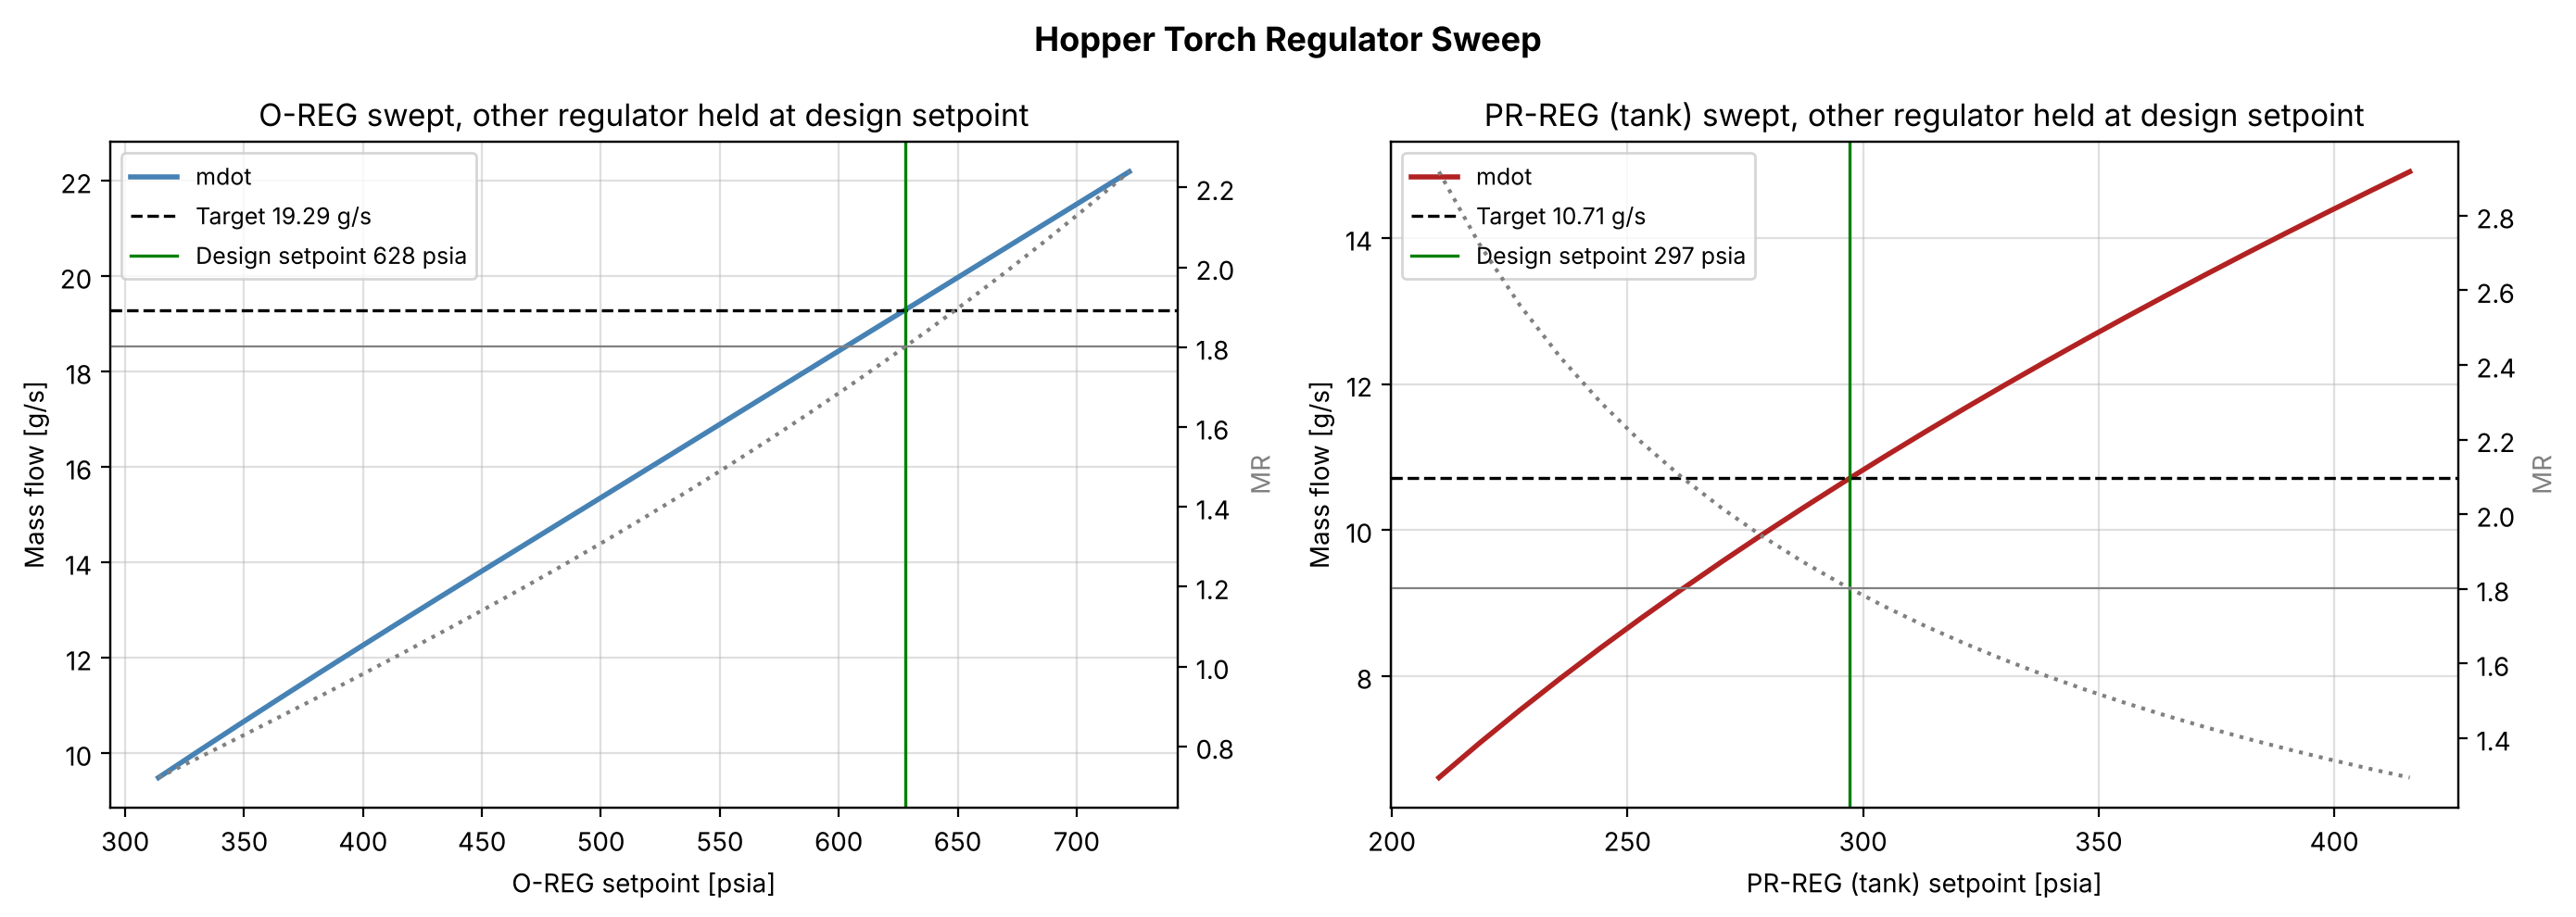

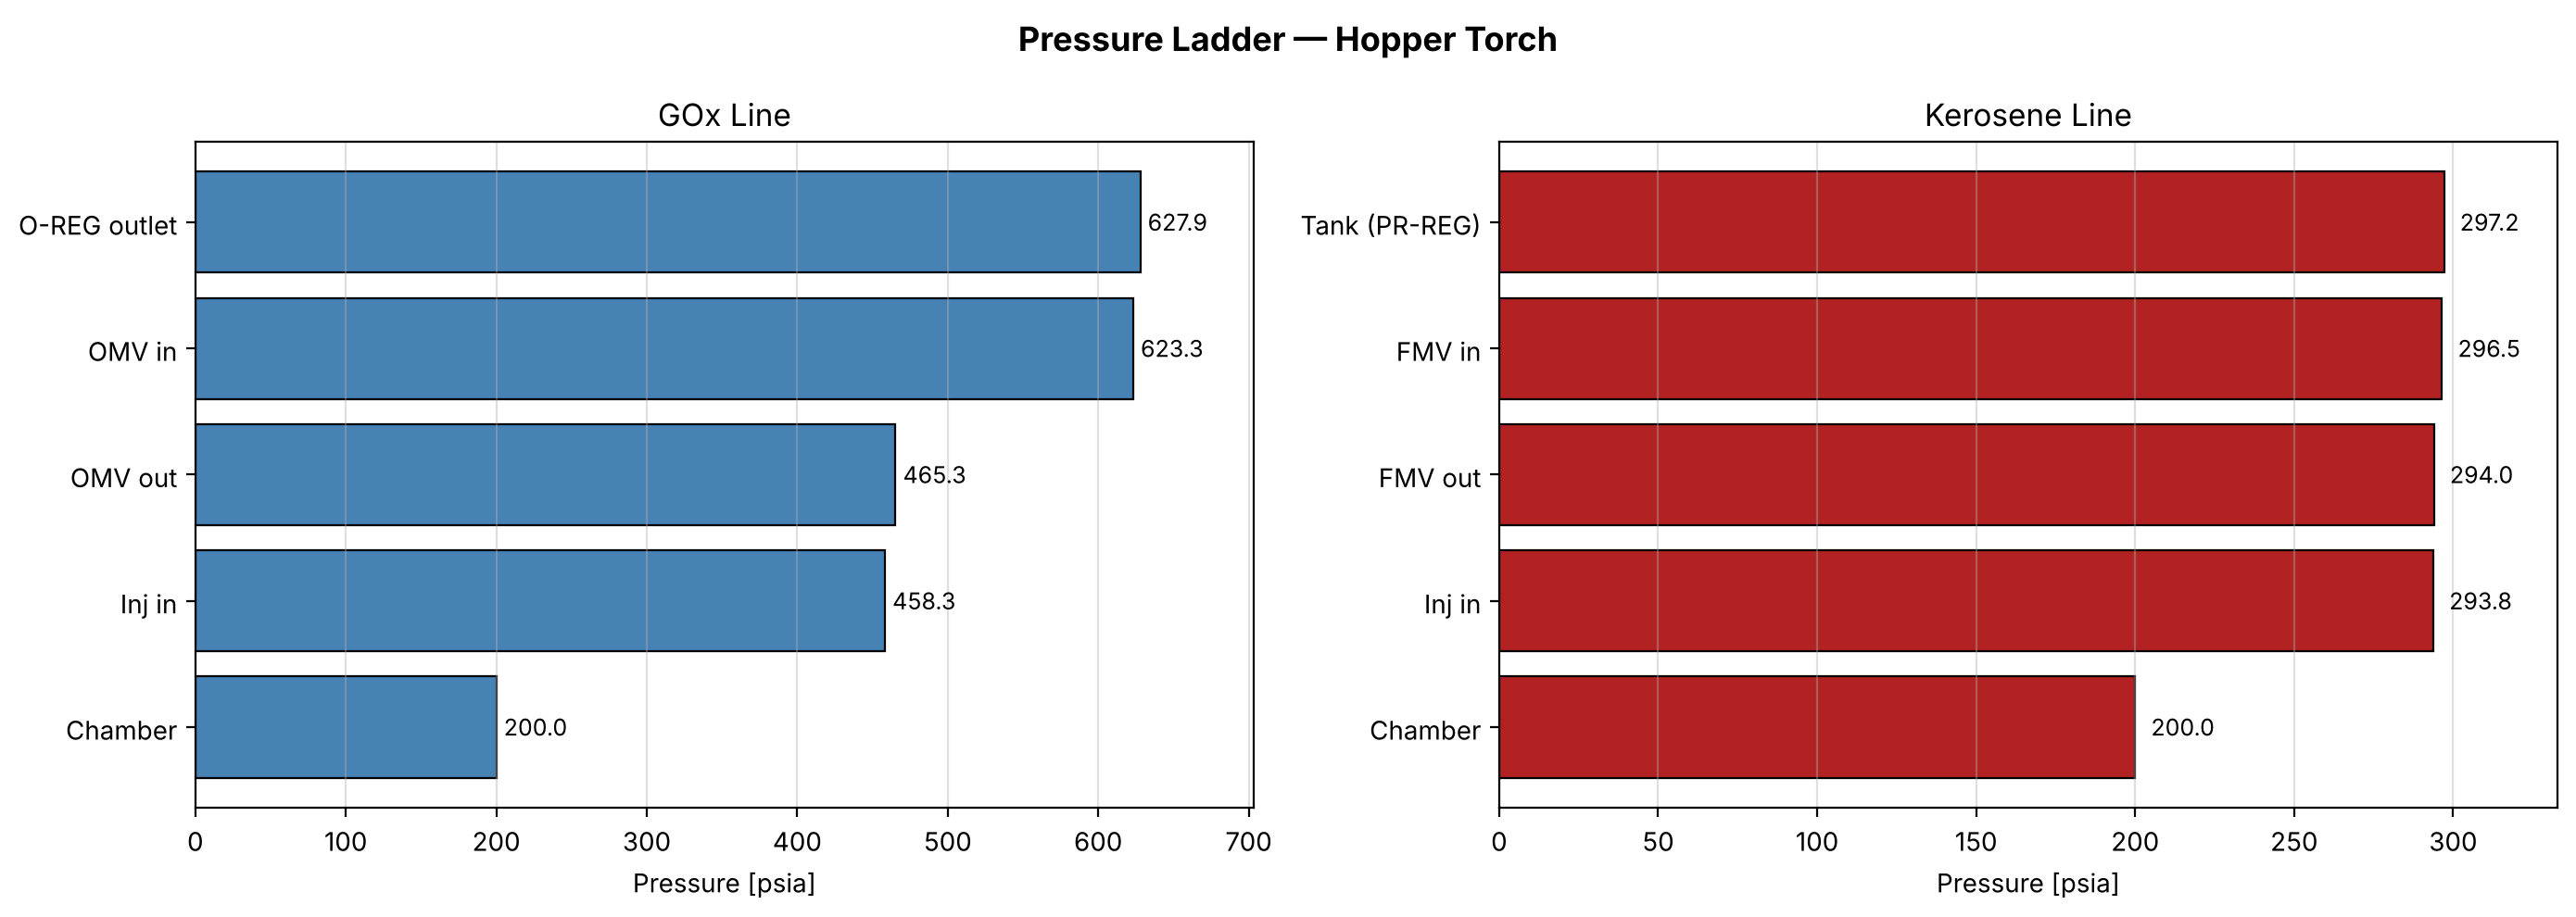

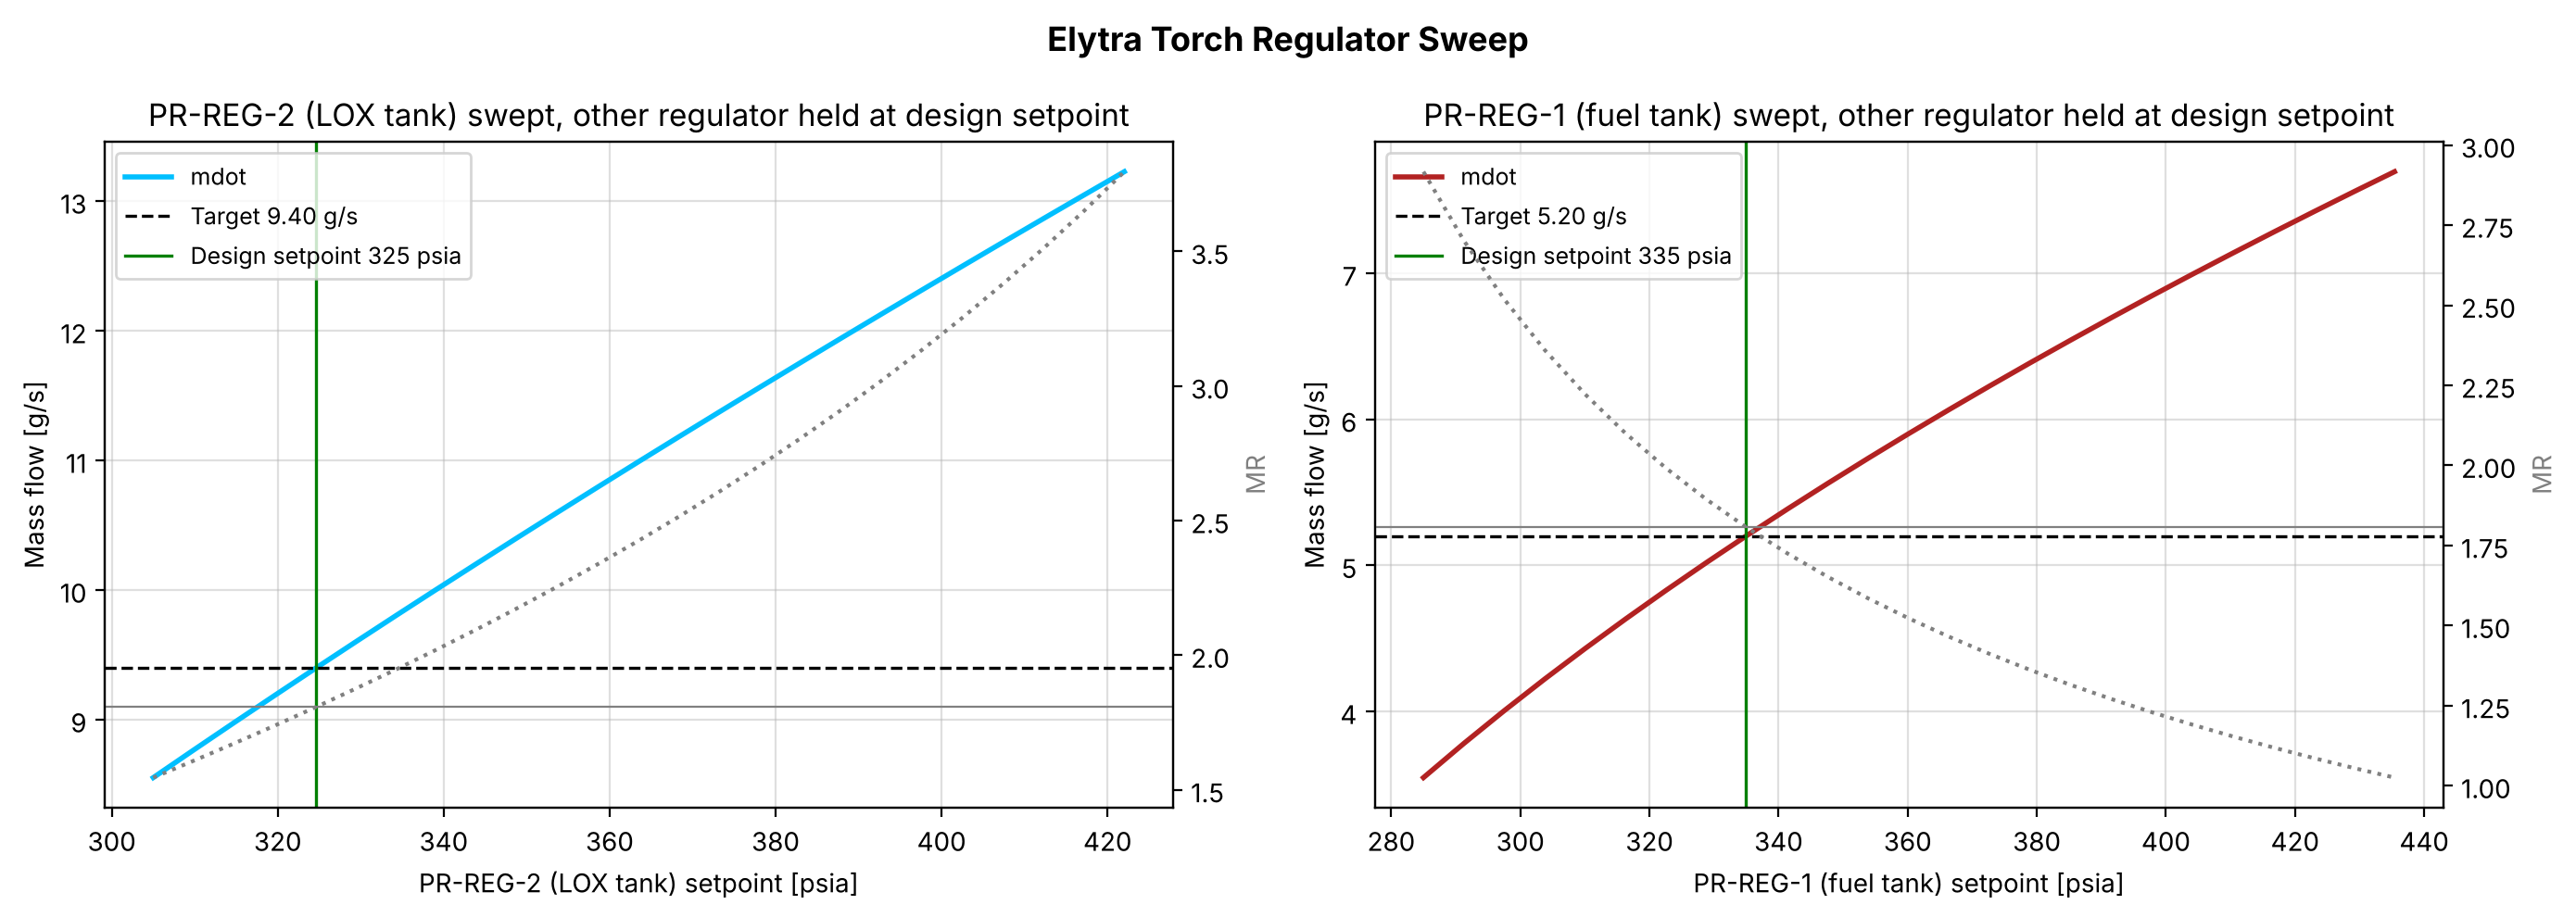

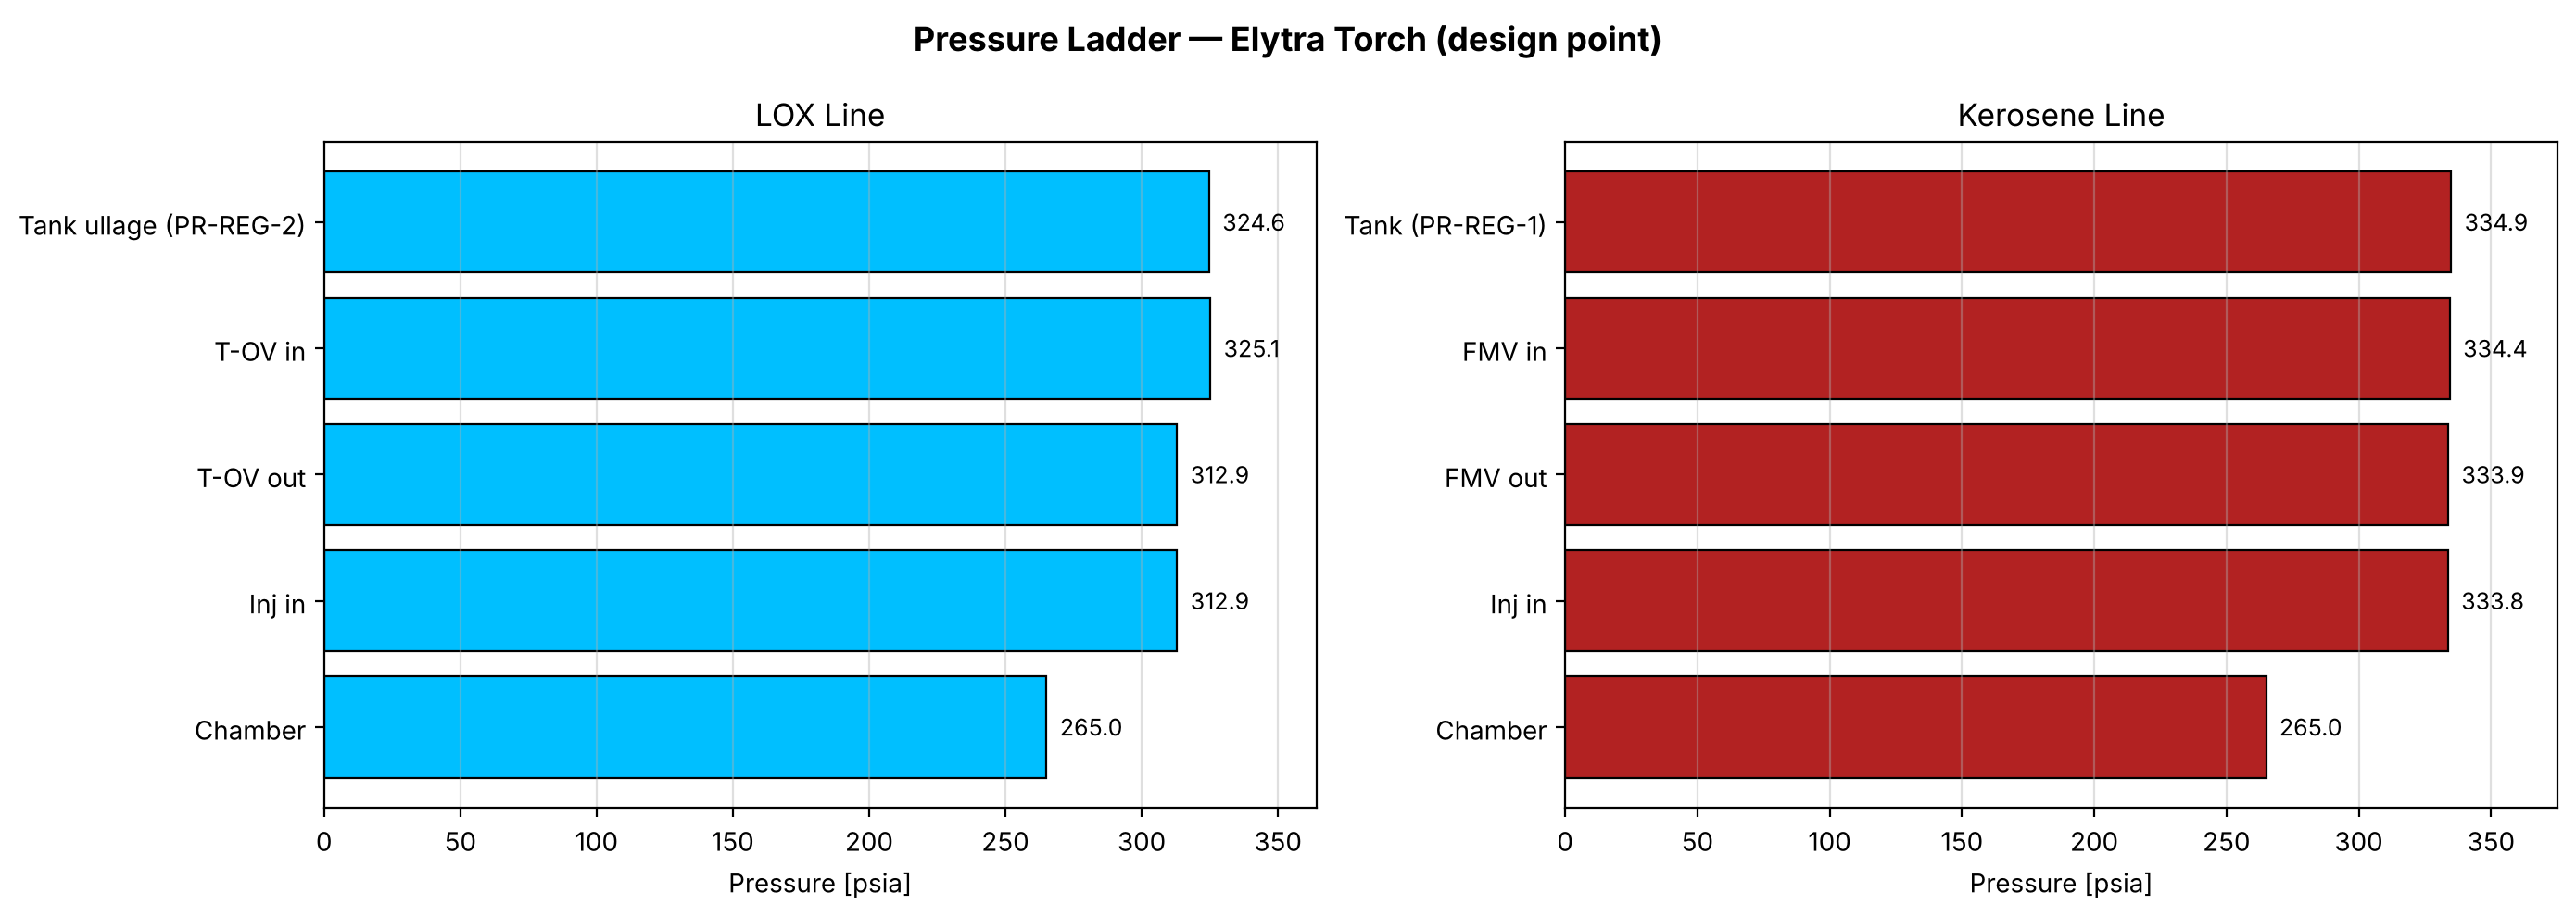

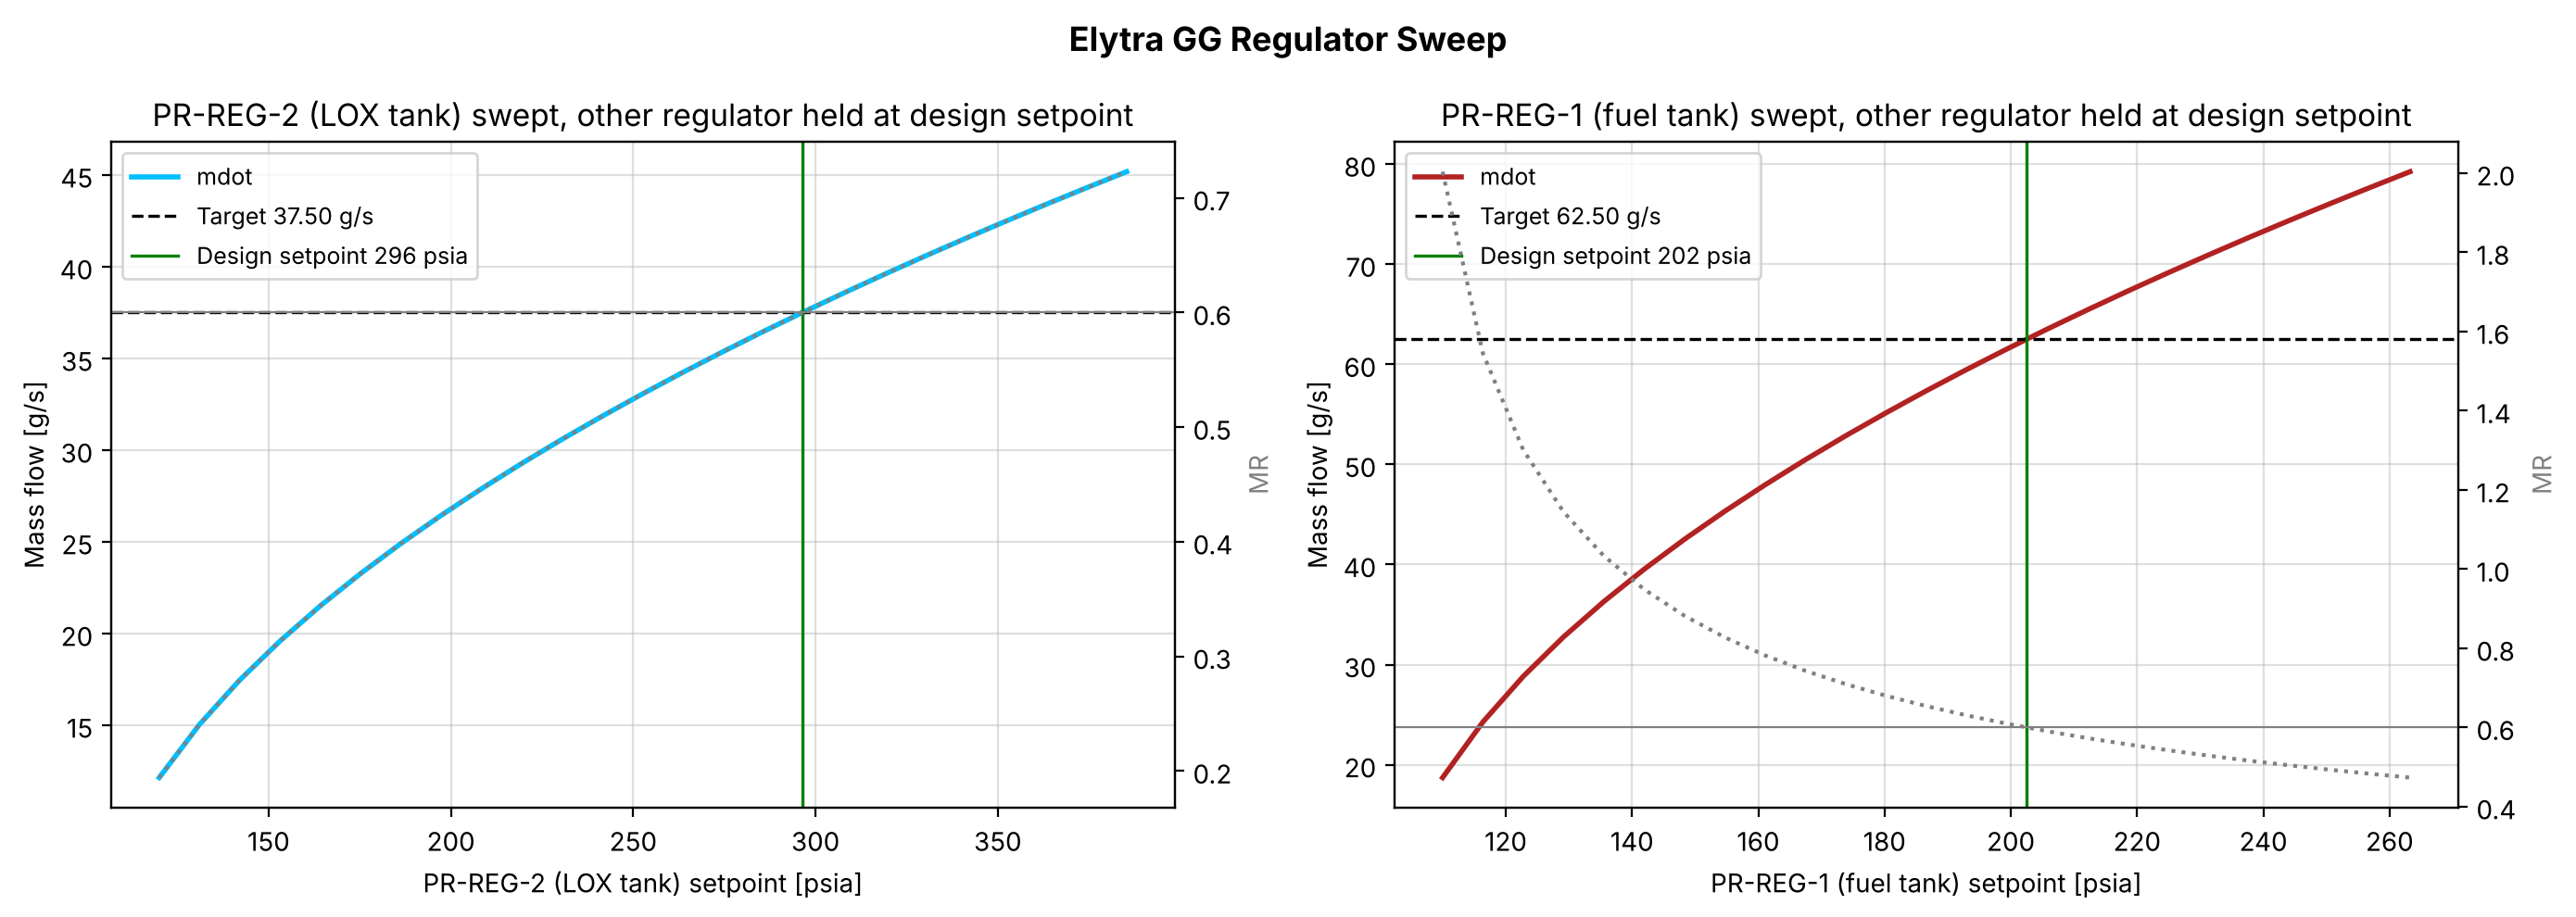

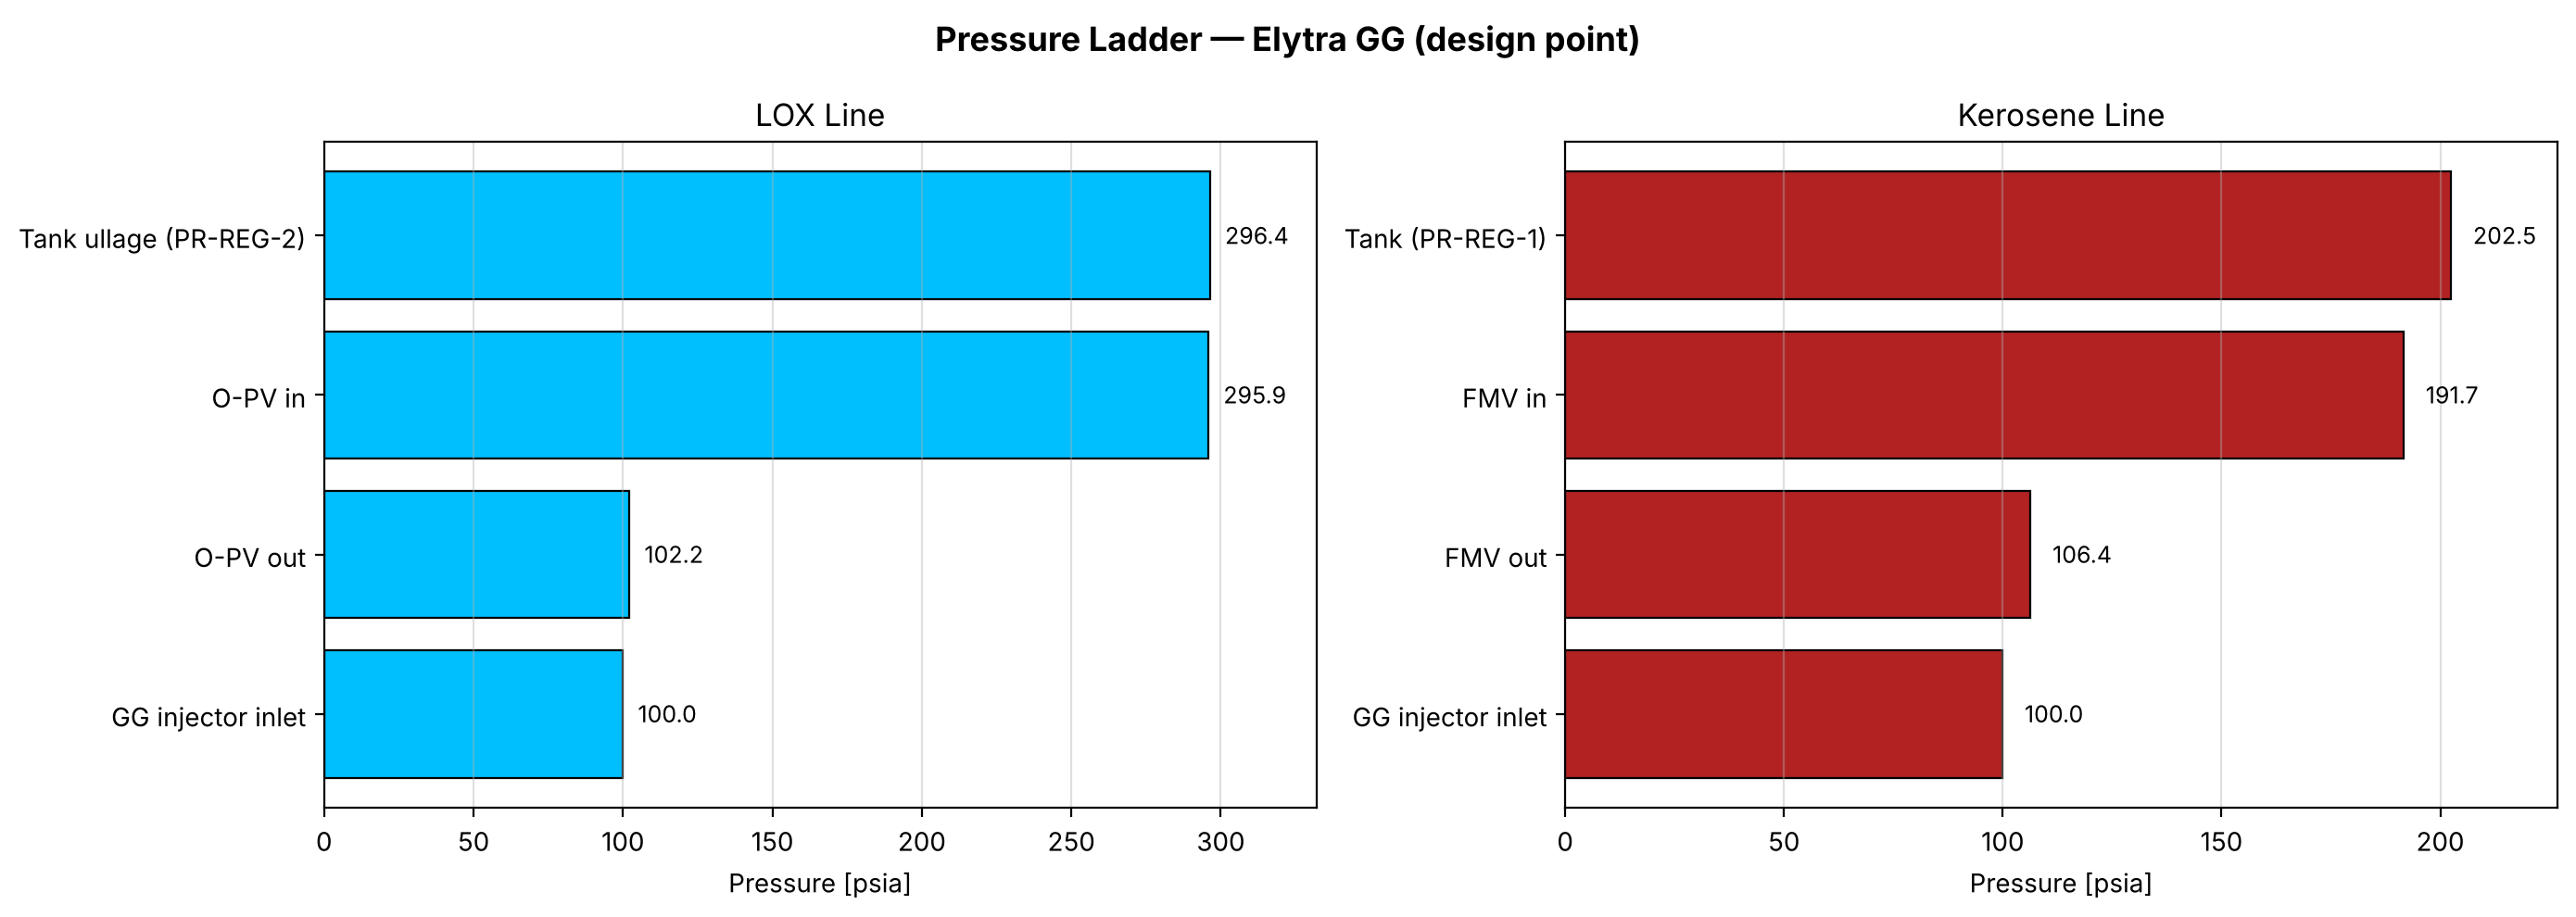

In [12]:
# ─────────────────────────────────────────────────────────────────────
# VISUALIZATION (all plots: Hopper torch, Elytra torch, Elytra GG)
# ─────────────────────────────────────────────────────────────────────

def plot_pressure_ladder(states: dict, title: str,
                         leg_labels: tuple = ('GOx Line', 'Kerosene Line'),
                         ox_color: str = 'steelblue',
                         fname: str = "pressure_ladder.png",
                         end_label: str = 'Chamber'):
    """ADDED (Elytra): leg_labels / ox_color / fname arguments; defaults reproduce the Hopper plot.
    end_label names the last bar (states['P_cc']): 'Chamber', or the GG injector inlet."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"Pressure Ladder — {title}", fontsize=13, fontweight='bold')
    Pc = states['P_cc'].value / PSI_TO_PA
    for ax, leg, label, color in ((axes[0], 'o_nodes', leg_labels[0], ox_color),
                                  (axes[1], 'f_nodes', leg_labels[1], 'firebrick')):
        names = list(states[leg].keys()) + [end_label]
        P = [s.value / PSI_TO_PA for s in states[leg].values()] + [Pc]
        bars = ax.barh(names[::-1], P[::-1], color=color, edgecolor='black', linewidth=0.8)
        for bar, val in zip(bars, P[::-1]):
            ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
                    f'{val:.1f}', va='center', fontsize=9)
        ax.set_xlim(0, max(P) * 1.12)
        ax.set_xlabel("Pressure [psia]"); ax.set_title(label)
        ax.grid(True, axis='x', alpha=0.4)
    plt.tight_layout()
    plt.savefig(script_dir / fname, dpi=150)
    plt.show()


def plot_regulator_sweep(ta, P_sweep_ox, sw_ox, P_req_ox, P_sweep_fu, sw_fu, P_req_fu,
                         reg_labels: tuple = ('O-REG', 'PR-REG (tank)'),
                         ox_color: str = 'steelblue',
                         fname: str = "regulator_sweep.png"):
    """ADDED (Elytra): reg_labels / ox_color / fname arguments; title now uses ta['name']
    (prints "Hopper Torch Regulator Sweep" for Hopper, as before)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{ta['name']} Regulator Sweep", fontsize=13, fontweight='bold')
    for ax, P_sweep, sw, key, target, P_req, label, color in (
        (axes[0], P_sweep_ox, sw_ox, 'mdot_ox_gs', ta['target_mdot_ox'], P_req_ox, reg_labels[0], ox_color),
        (axes[1], P_sweep_fu, sw_fu, 'mdot_fu_gs', ta['target_mdot_fu'], P_req_fu, reg_labels[1], 'firebrick'),
    ):
        ax.plot(P_sweep, sw[key], color=color, linewidth=2, label='mdot')
        ax.axhline(target * 1000, color='black', linestyle='--', linewidth=1.2,
                   label=f'Target {target*1000:.2f} g/s')
        ax.axvline(P_req, color='green', linewidth=1.2, label=f'Design setpoint {P_req:.0f} psia')
        ax.set_xlabel(f"{label} setpoint [psia]"); ax.set_ylabel("Mass flow [g/s]")
        ax2 = ax.twinx()
        ax2.plot(P_sweep, sw['MR'], color='gray', linestyle=':', linewidth=1.5, label='MR')
        ax2.axhline(ta['target_MR'], color='gray', linewidth=0.8)
        ax2.set_ylabel("MR", color='gray')
        ax.set_title(f"{label} swept, other regulator held at design setpoint")
        ax.legend(loc='upper left', fontsize=9); ax.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(script_dir / fname, dpi=150)
    plt.show()


if __name__ == "__main__":

    # Hopper torch
    plot_regulator_sweep(TA, P_sweep_ox, sw_ox, design['P_oreg_psia'],
                         P_sweep_fu, sw_fu, design['P_tank_psia'])
    plot_pressure_ladder(d_states, "Hopper Torch")

    # Elytra torch
    plot_regulator_sweep(TA_E, P_sweep_lox, e_sw_ox, e_design['P_lox_tank_psia'],
                         P_sweep_fu_e, e_sw_fu, e_design['P_fuel_tank_psia'],
                         reg_labels=('PR-REG-2 (LOX tank)', 'PR-REG-1 (fuel tank)'),
                         ox_color='deepskyblue', fname="elytra_regulator_sweep.png")
    plot_pressure_ladder(e_d_states, "Elytra Torch (design point)",
                         leg_labels=('LOX Line', 'Kerosene Line'), ox_color='deepskyblue',
                         fname="elytra_pressure_ladder.png")

    # Elytra gas generator
    plot_regulator_sweep(TA_G, P_sweep_lox_g, g_sw_ox, g_design['P_lox_tank_psia'],
                         P_sweep_fu_g, g_sw_fu, g_design['P_fuel_tank_psia'],
                         reg_labels=('PR-REG-2 (LOX tank)', 'PR-REG-1 (fuel tank)'),
                         ox_color='deepskyblue', fname="elytra_gg_regulator_sweep.png")
    plot_pressure_ladder(g_d_states, "Elytra GG (design point)",
                         leg_labels=('LOX Line', 'Kerosene Line'), ox_color='deepskyblue',
                         fname="elytra_gg_pressure_ladder.png", end_label='GG injector inlet')